# Giai đoạn 3d: Chuỗi kiểu ngày (sequential patterns)

**Loại công việc:** chủ yếu là **data mining** (khai phá mẫu tuần tự, *sequential pattern mining*). Mục 2 (ma trận chuyển) là **analysis** thống kê mô tả. Mục 3 so sánh bậc của mô hình Markov bằng log-loss ngoài mẫu theo năm, tức là **đánh giá kiểu ML**, nhưng mục tiêu vẫn là mô tả, không phải dự báo.

Notebook 04 gán cho mỗi ngày một **hình dạng** và một **bậc mức**:

| Mã | Hình dạng (log PM2.5 trừ trung bình ngày) |
|---|---|
| `S1_U` | cao ban đêm, thấp buổi chiều (hình chữ U) |
| `S2_tang` | tăng dần về tối |
| `S3_giam` | giảm dần trong ngày |
| `S4_phang` | phẳng, có bướu ban ngày |

Bậc mức: `thấp` ≤ 25, `TB` 25–50, `cao` > 50 µg/m³ (trung bình 24 giờ). Notebook 04 đã thấy sau một ngày `S2_tang` thì hôm sau trung bình **cao hơn** ~32%, sau `S3_giam` thì **thấp hơn** ~21%. Câu hỏi ở đây: *có những chuỗi kiểu ngày nào lặp lại, ví dụ `S2_tang` → `S1_U` → `S3_giam` mở rồi khép một đợt ô nhiễm, và chúng có vững qua các năm, các mùa không?*

## Chọn phương pháp

| Phương pháp | Ý tưởng | Hợp với dữ liệu này? |
|---|---|---|
| **Ma trận chuyển / Markov chain bậc 1** (**chọn**, mục 2) | xác suất kiểu ngày mai khi biết kiểu hôm nay | rất hợp: 4–12 trạng thái, chuỗi theo ngày đều nhau; dễ đọc; là đường nền cho các mục sau |
| Markov bậc 2, bậc k (mục 3, để kiểm tra) | kiểu ngày mai phụ thuộc 2 ngày gần nhất | cần nhiều dữ liệu; dùng để hỏi "chuỗi 3 ngày có thêm thông tin không" |
| **Episode mining kiểu WINEPI** (**chọn**, mục 4) | đếm các chuỗi liền nhau dài 2–4 ngày trong cửa sổ trượt; so với đường nền | hợp với một chuỗi dài duy nhất theo thời gian; cần đường nền để biết thế nào là "nhiều" |
| **PrefixSpan** (**chọn**, mục 5) | tìm chuỗi con (cho phép cách quãng) xuất hiện trong nhiều *chuỗi* của một cơ sở dữ liệu | cần nhiều chuỗi riêng biệt. Chạy trên cả dòng ngày thì gần như chuỗi 2–3 phần tử nào cũng "phổ biến". Vì vậy ta áp dụng trên **cơ sở dữ liệu các đợt ô nhiễm**, mỗi đợt là một chuỗi |
| GSP, SPADE | giống PrefixSpan, khác cách duyệt | cho cùng kết quả, PrefixSpan nhanh hơn và dễ cài |
| MINEPI | đếm theo lần xuất hiện tối thiểu thay cho cửa sổ | khác biệt nhỏ khi chuỗi liền nhau theo ngày |
| Hidden Markov Model | trạng thái ẩn sinh ra đường cong theo giờ | là mô hình (ML) chứ không phải liệt kê mẫu; kết quả khó so với nhãn đã có; để dành nếu muốn mô hình hóa đợt |
| Motif discovery trên chuỗi giờ (matrix profile) | tìm đoạn đường cong theo giờ giống nhau | bỏ qua nhãn ngày; hợp với câu hỏi khác |

**Vì sao cần đường nền:** mùa làm nhiễu mọi thứ. Mùa Thu nhiều `S1_U`, nên `S1_U → S1_U` xuất hiện nhiều chỉ vì Thu nhiều `S1_U`. Ta luôn so với kỳ vọng **trong cùng mùa**, như notebook 05:
- **Đường nền độc lập:** mỗi ngày rút ngẫu nhiên theo tỷ lệ kiểu ngày của mùa đó. Chuỗi vượt đường nền này là chuỗi *hay đi cùng nhau*.
- **Đường nền Markov bậc 1:** ngày sau chỉ phụ thuộc ngày trước. Chuỗi 3–4 ngày vượt đường nền này là chuỗi có "trí nhớ" dài hơn một ngày, không chỉ là hai cặp chuyển mạnh nối lại.

Đầu vào: `data/day_clusters.parquet` (notebook 04), `data/day_anomaly.csv` (notebook 06), `../phase1/data/clean/hanoi_daily.parquet` và `hanoi_hourly_enriched.parquet` (cờ lỗi đo, đường cong theo giờ). Đầu ra: `data/day_sequences.csv`, `data/transitions_by_season.csv`, `data/seq_patterns.csv`, `data/episodes.csv`, `data/episode_patterns.csv`, hình `reports/40_*` … `reports/47_*`.

**Nhắc lại:** mọi kết quả là **mối liên hệ theo thời gian** (kiểu A thường đi trước kiểu B), không phải A *gây ra* B. Cả hai thường cùng do một diễn biến thời tiết nhiều ngày. Dữ liệu từ **một trạm** (Đại sứ quán Mỹ, Ba Đình).

In [1]:
from pathlib import Path
import os, warnings
from itertools import product
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 200)

BASE = Path(os.environ.get("HANOI_AQ_DIR", ".."))
CLEAN = BASE / "phase1" / "data" / "clean"
REPORT = Path("reports"); REPORT.mkdir(exist_ok=True)
OUT = Path("data"); OUT.mkdir(exist_ok=True)
SEED = 0
rng = np.random.default_rng(SEED)
HCOLS = [f"pm25_h{i:02d}" for i in range(24)]
SEASON = {12: "Đông", 1: "Đông", 2: "Đông", 3: "Xuân", 4: "Xuân", 5: "Hè", 6: "Hè", 7: "Hè", 8: "Hè", 9: "Hè", 10: "Thu", 11: "Thu"}
SEASONS = ["Đông", "Xuân", "Hè", "Thu"]
SHAPES = ["S1_U", "S2_tang", "S3_giam", "S4_phang"]
LEVELS = ["thấp", "TB", "cao"]
DAYTYPES = [f"{s}|{l}" for s in SHAPES for l in LEVELS]
SHORT = {"S1_U": "U", "S2_tang": "Tăng", "S3_giam": "Giảm", "S4_phang": "Phẳng"}

cl = pd.read_parquet(OUT / "day_clusters.parquet"); cl.index = pd.to_datetime(cl.index)
an = pd.read_csv(OUT / "day_anomaly.csv", parse_dates=["date"]).set_index("date")
D = pd.read_parquet(CLEAN / "hanoi_daily.parquet"); D.index = pd.to_datetime(D.index)
hz = pd.read_parquet(CLEAN / "hanoi_hourly_enriched.parquet", columns=["flag_suspect_zero", "date"])
print("ngày có nhãn (notebook 04):", len(cl), "|", cl.index.min().date(), "→", cl.index.max().date())

ngày có nhãn (notebook 04): 2230 | 2016-02-01 → 2025-04-08


## 1. Kiểm tra chất lượng chuỗi (analysis)

Với chuỗi, chất lượng dữ liệu quan trọng hơn ở các notebook trước: **một ngày thiếu làm đứt mọi chuỗi đi qua nó**, và nếu ta "nối" hai ngày cách nhau một khoảng trống thì sẽ tạo ra cặp chuyển không có thật.

Các loại ngày không có nhãn:
1. Ngày không có dữ liệu hoặc < 18 giờ đo thật (notebook 01, 04).
2. Ngày **nghi lỗi đo**: Giai đoạn 1 đổi thành NaN các giờ ≤ 3 µg/m³ trong ngày có ≥ 6 giờ như vậy (`flag_suspect_zero`, 26 ngày). Lần chạy đầu notebook 06 thấy 17 ngày trong số đó vẫn được dùng; sau khi sửa, ta kiểm tra lại là không ngày nào còn nhãn.
3. Ngày **cạnh lỗi đo** (ngay trước/sau một ngày nghi lỗi): vẫn có nhãn, nhưng máy đo có thể chưa ổn định (ví dụ 8/4/2019 nhảy lên 358 µg/m³ sau hai ngày gần 0). Ta giữ chúng ở phân tích chính và **chạy lại không có chúng** ở mục 6.

In [2]:
idx = pd.date_range(cl.index.min(), cl.index.max(), freq="D")
S = pd.DataFrame(index=idx); S.index.name = "date"
S["shape"] = cl["shape_code"].astype(object).reindex(idx)
S["level"] = cl["level_tier"].astype(object).reindex(idx)
S["day_type"] = cl["day_type"].astype(object).reindex(idx)
S["pm25_mean"] = cl["pm25_mean"].reindex(idx)
S["season"] = [SEASON[m] for m in idx.month]
S["year"] = idx.year

susp = pd.to_datetime(pd.Series(sorted(set(hz.loc[hz["flag_suspect_zero"], "date"].astype(str)))))
nb06_flag = an.index[an["nghi_loi_do"] == True]
S["suspect"] = S.index.isin(susp) | S.index.isin(nb06_flag)
S["present"] = S["shape"].notna()
assert not (S["suspect"] & S["present"]).any(), "có ngày nghi lỗi đo vẫn còn nhãn"
near = set()
for d in S.index[S["suspect"]]:
    near |= {d - pd.Timedelta(days=1), d + pd.Timedelta(days=1)}
S["near_fault"] = S.index.isin(sorted(near)) & S["present"]

# Đoạn liên tục (segment): các ngày có nhãn liền nhau; mỗi ngày thiếu hoặc nghi lỗi đo là một chỗ cắt
S["seg"] = (S["present"] != S["present"].shift()).cumsum().where(S["present"])
S["pos"] = S.groupby("seg").cumcount().where(S["present"])
seg_len = S.dropna(subset=["seg"]).groupby("seg").size()

print(f"Khoảng ngày: {len(S)} | có nhãn: {S['present'].sum()} ({S['present'].mean():.0%}) | thiếu: {(~S['present']).sum()}")
print(f"Ngày nghi lỗi đo (cờ Giai đoạn 1 + notebook 06): {S['suspect'].sum()} | còn nhãn: 0 (đã kiểm tra) | ngày cạnh lỗi đo còn nhãn: {S['near_fault'].sum()}")
print(f"Số đoạn liên tục: {len(seg_len)} | dài 1 ngày: {(seg_len == 1).sum()} | ≥ 3 ngày: {(seg_len >= 3).sum()} (chứa {seg_len[seg_len >= 3].sum()} ngày)")
print(f"Số cặp ngày liền nhau dùng được: {(seg_len - 1).sum()} | số bộ 3 ngày liền: {(seg_len - 2).clip(lower=0).sum()}")
gap = (~S["present"]).astype(int); gl = gap.groupby((gap != gap.shift()).cumsum()).agg(["first", "size"]); gl = gl[gl["first"] == 1]["size"]
print("độ dài khoảng thiếu (ngày):", gl.describe()[["count", "50%", "mean", "max"]].round(1).to_dict())

Khoảng ngày: 3355 | có nhãn: 2230 (66%) | thiếu: 1125
Ngày nghi lỗi đo (cờ Giai đoạn 1 + notebook 06): 26 | còn nhãn: 0 (đã kiểm tra) | ngày cạnh lỗi đo còn nhãn: 20
Số đoạn liên tục: 201 | dài 1 ngày: 41 | ≥ 3 ngày: 144 (chứa 2157 ngày)
Số cặp ngày liền nhau dùng được: 2029 | số bộ 3 ngày liền: 1869
độ dài khoảng thiếu (ngày): {'count': 200.0, '50%': 2.0, 'mean': 5.6, 'max': 134.0}


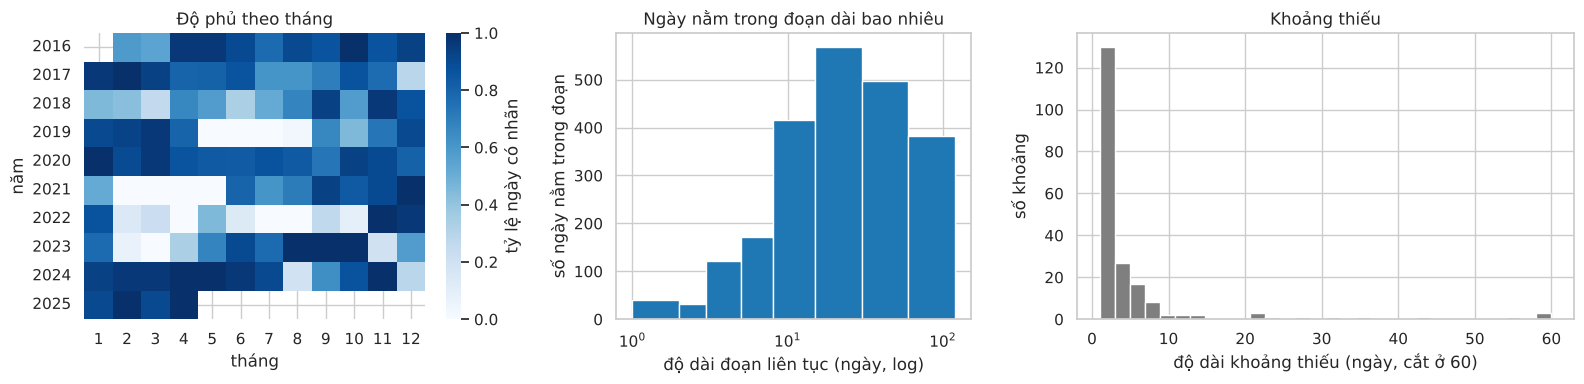

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={"width_ratios": [1.2, 1, 1.4]})
cov = S.groupby([S.index.year, S.index.month])["present"].mean().unstack()
sns.heatmap(cov, ax=ax[0], cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "tỷ lệ ngày có nhãn"})
ax[0].set(xlabel="tháng", ylabel="năm", title="Độ phủ theo tháng")
bins = [1, 2, 3, 5, 8, 15, 30, 60, 120]
ax[1].hist(seg_len, bins=bins, weights=seg_len, color="tab:blue", edgecolor="w")
ax[1].set_xscale("log"); ax[1].set(xlabel="độ dài đoạn liên tục (ngày, log)", ylabel="số ngày nằm trong đoạn", title="Ngày nằm trong đoạn dài bao nhiêu")
ax[2].hist(gl.clip(upper=60), bins=30, color="tab:gray")
ax[2].set(xlabel="độ dài khoảng thiếu (ngày, cắt ở 60)", ylabel="số khoảng", title="Khoảng thiếu")
plt.tight_layout(); plt.savefig(REPORT / "40_sequence_coverage.png"); plt.show()

**Thiếu có phụ thuộc vào kiểu ngày không?** Nếu máy đo hay hỏng sau những ngày ô nhiễm cao (ví dụ quá tải), thì các đợt cao sẽ bị cắt cụt nhiều hơn và ta sẽ thấy ít chuỗi "khép đợt" hơn thực tế. Kiểm tra: tỷ lệ "ngày mai thiếu" theo kiểu ngày hôm nay, so bằng chi-square.

In [4]:
nxt_missing = (~S["present"].shift(-1, fill_value=False)).where(S["present"])
prv_missing = (~S["present"].shift(1, fill_value=False)).where(S["present"])
for col in ["shape", "level"]:
    t = pd.crosstab(S.loc[S["present"], col], nxt_missing[S["present"]].astype(bool))
    chi2, p, *_ = stats.chi2_contingency(t)
    rate = (t[True] / t.sum(axis=1)).round(3)
    print(f"P(ngày mai thiếu | {col} hôm nay):", rate.to_dict(), f"| chi2 p = {p:.2f}")
    t2 = pd.crosstab(S.loc[S["present"], col], prv_missing[S["present"]].astype(bool))
    print(f"P(hôm qua thiếu | {col} hôm nay):", (t2[True] / t2.sum(axis=1)).round(3).to_dict(), f"| chi2 p = {stats.chi2_contingency(t2)[1]:.2f}")

P(ngày mai thiếu | shape hôm nay): {'S1_U': 0.082, 'S2_tang': 0.092, 'S3_giam': 0.083, 'S4_phang': 0.098} | chi2 p = 0.74
P(hôm qua thiếu | shape hôm nay): {'S1_U': 0.095, 'S2_tang': 0.101, 'S3_giam': 0.074, 'S4_phang': 0.09} | chi2 p = 0.53
P(ngày mai thiếu | level hôm nay): {'TB': 0.099, 'cao': 0.076, 'thấp': 0.092} | chi2 p = 0.25
P(hôm qua thiếu | level hôm nay): {'TB': 0.085, 'cao': 0.084, 'thấp': 0.108} | chi2 p = 0.28


**Đọc kết quả:** tỷ lệ "ngày mai thiếu" gần như như nhau ở mọi kiểu ngày (khoảng 8–10%, chi-square p ≥ 0,25). Nghĩa là máy đo không hỏng nhiều hơn sau ngày ô nhiễm cao hay sau một hình dạng cụ thể, nên việc **cắt chuỗi tại ngày thiếu không làm lệch** tỷ lệ các kiểu chuyển. Cái giá là mất dữ liệu: chỉ 66% số ngày có nhãn, độ phủ rất khác nhau giữa các năm (2022 chỉ khoảng 35%), và như mục 5 sẽ thấy, khoảng 40% đợt ô nhiễm bị cắt ở ít nhất một đầu.

**Cách xử lý ngày thiếu (lựa chọn của notebook):**

| Cách | Ưu | Nhược |
|---|---|---|
| **Cắt chuỗi tại ngày thiếu** (**chọn**) | không tạo ra cặp chuyển giả; đơn giản | mất các chuỗi đi qua khoảng thiếu; đoạn ngắn đóng góp ít |
| Nối qua khoảng thiếu 1 ngày (coi như A → B) | giữ thêm dữ liệu | A → B thật ra là A → ? → B, làm loãng ma trận chuyển |
| Điền nhãn (nội suy, hay HMM với quan sát thiếu) | chuỗi đầy đủ | nhãn điền là do mô hình đoán; dễ tạo ra đúng mẫu ta đang tìm |
| Thêm ký hiệu "thiếu" vào bảng chữ cái | thấy rõ chỗ đứt | mẫu chứa "thiếu" không có ý nghĩa vật lý |

Mọi cặp, bộ ba, bộ bốn ngày chỉ được đếm khi **tất cả các ngày đều có nhãn và liền nhau**. Đoạn chuỗi bắt đầu ở mùa này và kết thúc ở mùa khác được gán theo **mùa của ngày đầu tiên**.

In [5]:
def windows(col, L):
    # Mọi cửa sổ L ngày liền nhau nằm trọn trong một đoạn; trả về DataFrame: ngày đầu, mùa, năm, các ký hiệu
    v = S[col].values; seg = S["seg"].values; n = len(S)
    ok = np.ones(n - L + 1, bool)
    for j in range(L):
        ok &= ~pd.isna(seg[j:n - L + 1 + j])
    for j in range(1, L):
        ok &= seg[j:n - L + 1 + j] == seg[:n - L + 1]
    st = np.where(ok)[0]
    W = pd.DataFrame({f"x{j}": v[st + j] for j in range(L)})
    W["date"] = S.index[st]; W["season"] = S["season"].values[st]; W["year"] = S["year"].values[st]
    W["near_fault"] = np.any([S["near_fault"].values[st + j] for j in range(L)], axis=0)
    return W

W2s, W2d = windows("shape", 2), windows("day_type", 2)
print("cặp ngày theo mùa:", W2s["season"].value_counts().reindex(SEASONS).to_dict())

cặp ngày theo mùa: {'Đông': 556, 'Xuân': 311, 'Hè': 765, 'Thu': 397}


## 2. Ma trận chuyển theo mùa (analysis)

Với mỗi mùa, ước lượng `P(kiểu ngày mai = b | kiểu hôm nay = a)` bằng tần suất. So với tỷ lệ của `b` trong cùng mùa bằng **lift** = P(b | a) / P(b), giống lift của association rules:
- lift > 1: sau `a` thì `b` hay xuất hiện hơn bình thường.
- Đường chéo lớn nghĩa là kiểu ngày **bền** (hôm nay sao thì mai hay vậy). Độ dài trung bình một chuỗi cùng kiểu theo Markov là 1 / (1 − P(a → a)).

Kiểm định: chi-square độc lập cho cả bảng trong mỗi mùa, và Fisher cho từng ô (a → b so với a → khác), hiệu chỉnh Benjamini–Hochberg (BH) như notebook 05.

In [6]:
def bh(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    q = np.empty(n); q[o] = np.minimum.accumulate((p[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.minimum(q, 1)

def trans_table(W, states, season=None):
    w = W if season is None else W[W["season"] == season]
    C = pd.crosstab(w["x0"], w["x1"]).reindex(index=states, columns=states, fill_value=0)
    return C

rows = []
for col, W, states in [("shape", W2s, SHAPES), ("level", windows("level", 2), LEVELS), ("day_type", W2d, DAYTYPES)]:
    for s in SEASONS:
        C = trans_table(W, states, s); N = C.values.sum()
        P = C.div(C.sum(axis=1), axis=0); base = C.sum(axis=0) / N
        chi2, p_all, *_ = stats.chi2_contingency(C.loc[C.sum(axis=1) > 0, C.sum(axis=0) > 0])
        for a in states:
            for b in states:
                n_ab = C.loc[a, b]; n_a = C.loc[a].sum(); n_b = C[b].sum()
                if n_a == 0: continue
                tab = [[n_ab, n_a - n_ab], [n_b - n_ab, N - n_a - n_b + n_ab]]
                rows.append(dict(bang=col, season=s, tu=a, den=b, n=n_ab, n_tu=n_a, p_cond=P.loc[a, b], p_base=base[b],
                                 lift=P.loc[a, b] / base[b] if base[b] > 0 else np.nan,
                                 p_fisher=stats.fisher_exact(tab, alternative="greater")[1], p_bang=p_all))
T = pd.DataFrame(rows)
T["q"] = np.nan
for col in T["bang"].unique():
    m = T["bang"] == col; T.loc[m, "q"] = bh(T.loc[m, "p_fisher"])
T.to_csv(OUT / "transitions_by_season.csv", index=False)
print(T[T["bang"] != "day_type"].groupby(["bang", "season"])["p_bang"].first().map("{:.1e}".format).unstack())

season       Hè      Thu     Xuân     Đông
bang                                      
level   1.3e-45  9.8e-42  1.5e-22  1.9e-45
shape   5.6e-05  1.8e-08  1.4e-05  5.2e-10


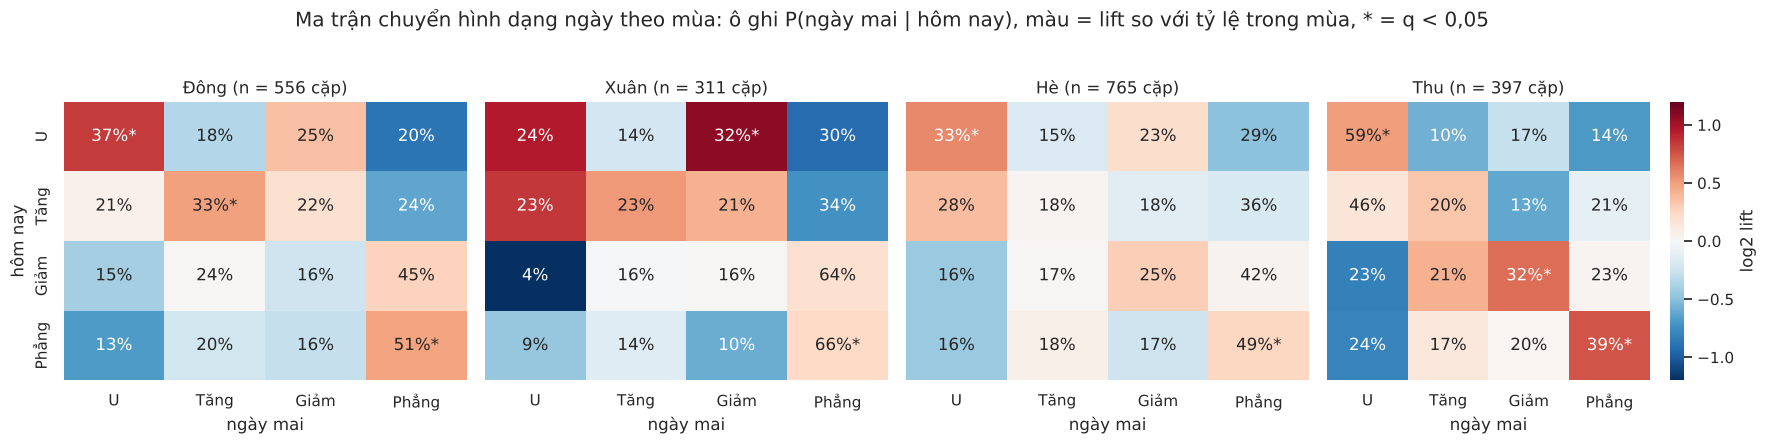

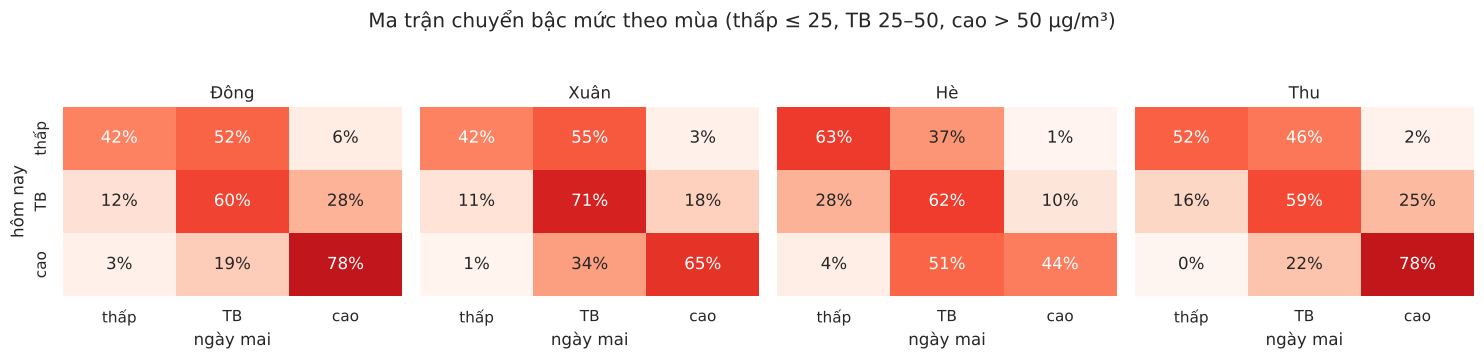

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3), sharey=True)
for ax, s in zip(axes, SEASONS):
    t = T[(T["bang"] == "shape") & (T["season"] == s)]
    L = t.pivot(index="tu", columns="den", values="lift").reindex(index=SHAPES, columns=SHAPES)
    P = t.pivot(index="tu", columns="den", values="p_cond").reindex(index=SHAPES, columns=SHAPES)
    Q = t.pivot(index="tu", columns="den", values="q").reindex(index=SHAPES, columns=SHAPES)
    ann = P.map(lambda v: f"{v:.0%}") + Q.map(lambda q: "*" if q < 0.05 else "")
    sns.heatmap(np.log2(L), ax=ax, cmap="RdBu_r", center=0, vmin=-1.2, vmax=1.2, annot=ann, fmt="", cbar=s == "Thu",
                cbar_kws={"label": "log2 lift"}, xticklabels=[SHORT[x] for x in SHAPES], yticklabels=[SHORT[x] for x in SHAPES])
    ax.set(title=f"{s} (n = {int(t['n'].sum())} cặp)", xlabel="ngày mai", ylabel="hôm nay" if s == "Đông" else "")
fig.suptitle("Ma trận chuyển hình dạng ngày theo mùa: ô ghi P(ngày mai | hôm nay), màu = lift so với tỷ lệ trong mùa, * = q < 0,05", y=1.03)
plt.tight_layout(); plt.savefig(REPORT / "41_transition_shape.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, s in zip(axes, SEASONS):
    t = T[(T["bang"] == "level") & (T["season"] == s)]
    P = t.pivot(index="tu", columns="den", values="p_cond").reindex(index=LEVELS, columns=LEVELS)
    sns.heatmap(P, ax=ax, cmap="Reds", vmin=0, vmax=1, annot=True, fmt=".0%", cbar=False)
    ax.set(title=f"{s}", xlabel="ngày mai", ylabel="hôm nay" if s == "Đông" else "")
fig.suptitle("Ma trận chuyển bậc mức theo mùa (thấp ≤ 25, TB 25–50, cao > 50 µg/m³)", y=1.05)
plt.tight_layout(); plt.savefig(REPORT / "42_transition_level.png", bbox_inches="tight"); plt.show()

In [8]:
# Độ bền: P(a → a), độ dài chuỗi kỳ vọng theo Markov và độ dài quan sát (chỉ đếm chuỗi có điểm đầu và cuối quan sát được)
def run_lengths(col):
    out = []
    for _, g in S.dropna(subset=["seg"]).groupby("seg"):
        v = g[col].values; r = (pd.Series(v) != pd.Series(v).shift()).cumsum().values
        for k in np.unique(r):
            m = r == k
            if m[0] or m[-1]: continue  # bị cắt bởi khoảng thiếu → độ dài không biết (censored)
            out.append(dict(state=v[m][0], length=m.sum(), season=g["season"].values[m][0]))
    return pd.DataFrame(out)
RL = run_lengths("shape")
pers = T[(T["bang"] == "shape") & (T["tu"] == T["den"])].pivot(index="tu", columns="season", values="p_cond")[SEASONS]
print("P(giữ nguyên hình dạng sang ngày mai):"); print(pers.round(2))
print("\nĐộ dài trung bình chuỗi cùng hình dạng: Markov 1/(1-p) | quan sát (chuỗi không bị cắt)")
print(pd.DataFrame({"Markov": (1 / (1 - pers)).mean(axis=1).round(2), "quan sát": RL.groupby("state")["length"].mean().round(2),
                    "số chuỗi": RL.groupby("state").size()}))
RLl = run_lengths("level")
print("\nĐộ dài trung bình chuỗi cùng bậc mức (quan sát):", RLl.groupby("state")["length"].agg(["mean", "max", "size"]).round(2).to_dict("index"))

P(giữ nguyên hình dạng sang ngày mai):
season    Đông  Xuân    Hè   Thu
tu                              
S1_U      0.37  0.24  0.33  0.59
S2_tang   0.33  0.23  0.18  0.20
S3_giam   0.16  0.16  0.25  0.32
S4_phang  0.51  0.66  0.49  0.39

Độ dài trung bình chuỗi cùng hình dạng: Markov 1/(1-p) | quan sát (chuỗi không bị cắt)
          Markov  quan sát  số chuỗi
S1_U        1.70      1.60       246
S2_tang     1.31      1.28       254
S3_giam     1.30      1.28       275
S4_phang    2.16      1.90       316

Độ dài trung bình chuỗi cùng bậc mức (quan sát): {'TB': {'mean': 2.52, 'max': 12, 'size': 288}, 'cao': {'mean': 3.16, 'max': 17, 'size': 139}, 'thấp': {'mean': 1.96, 'max': 9, 'size': 159}}


In [9]:
sig = T[(T["q"] < 0.05) & (T["lift"] >= 1.3) & (T["n"] >= 10)].sort_values(["bang", "season", "lift"], ascending=[True, True, False])
print("Cặp chuyển nổi bật (lift ≥ 1,3, q < 0,05, ≥ 10 lần):")
print(sig[["bang", "season", "tu", "den", "n", "p_cond", "p_base", "lift", "q"]].round(3).to_string(index=False))

Cặp chuyển nổi bật (lift ≥ 1,3, q < 0,05, ≥ 10 lần):
    bang season            tu           den   n  p_cond  p_base  lift     q
day_type     Hè     S1_U|thấp     S1_U|thấp  17   0.236   0.089 2.656 0.002
day_type     Hè  S3_giam|thấp S4_phang|thấp  17   0.405   0.173 2.346 0.007
day_type     Hè S4_phang|thấp S4_phang|thấp  48   0.358   0.173 2.076 0.000
day_type     Hè   S4_phang|TB   S4_phang|TB  57   0.345   0.218 1.582 0.001
day_type    Thu    S3_giam|TB    S3_giam|TB  11   0.289   0.088 3.283 0.004
day_type    Thu   S3_giam|cao   S3_giam|cao  10   0.270   0.098 2.751 0.032
day_type    Thu   S4_phang|TB   S4_phang|TB  10   0.263   0.098 2.679 0.038
day_type    Thu      S1_U|cao      S1_U|cao  59   0.602   0.244 2.464 0.000
day_type    Thu       S1_U|TB       S1_U|TB  13   0.283   0.121 2.337 0.030
day_type   Xuân  S4_phang|cao  S4_phang|cao  20   0.392   0.154 2.541 0.000
day_type   Xuân   S4_phang|TB   S4_phang|TB  67   0.604   0.357 1.691 0.000
day_type   Đông  S2_tang|thấp    S2

**Đọc kết quả (analysis):**
1. **Bậc mức rất bền**, hình dạng thì ít bền hơn nhiều. Hôm nay `cao` thì ngày mai vẫn `cao` với xác suất 78% ở Đông và Thu. Ở mùa Hè, ngày `cao` hiếm (9% số ngày) nhưng đã có thì 44% hôm sau vẫn cao (lift 4,9). Một chuỗi ngày `cao` dài trung bình 3,2 ngày, dài nhất 17 ngày.
2. Với hình dạng, tín hiệu chủ yếu là **tự lặp lại**: `U → U` (Thu 59%, Đông 37%) và `Phẳng → Phẳng` (Xuân 66%). Độ dài chuỗi cùng hình dạng quan sát được gần với dự đoán của Markov bậc 1 (ví dụ U: 1,6 so với 1,7 ngày), tức mô hình bậc 1 mô tả khá đúng độ bền.
3. Chuyển **giữa** các hình dạng thì yếu khi bỏ qua mức. Khi ghép hình dạng với mức (12 kiểu ngày), mùa Đông hiện ra một "cầu thang": `Tăng|thấp → Tăng|TB` (lift 4,6), `Tăng|TB → Tăng|cao` (2,4), `Tăng|cao → U|cao` (2,1), rồi `Tăng|cao → Giảm|cao` (2,8) và `U|cao → Giảm|cao` (2,3). Đây là hình ảnh một đợt tích tụ dần qua các buổi tối rồi tan trong một ngày.
4. Giới hạn: mỗi mùa chỉ có 300–770 cặp ngày, nên nhiều ô của bảng 12 × 12 chỉ có vài lần. Các ô có `*` là đã qua hiệu chỉnh BH, nhưng vẫn cần xem độ vững ở mục 6.

## 3. Chuỗi 3 ngày có thêm thông tin so với cặp ngày không? (đánh giá kiểu ML)

Câu hỏi "có chuỗi 3 ngày đặc trưng không" tương đương với hỏi Markov **bậc 2** có tốt hơn **bậc 1** không. Nếu bậc 1 đã đủ, thì một chuỗi như `Tăng → U → Giảm` chỉ là hai cặp chuyển mạnh `Tăng → U` và `U → Giảm` nối lại, không có "kịch bản 3 ngày" riêng.

So sánh bằng **log-loss** (trung bình −log P(kiểu ngày mai thật)) khi dự đoán ngoài mẫu: ước lượng xác suất trên các năm khác, đánh giá trên năm bỏ ra (*leave-one-year-out*), giống GroupKFold theo năm ở notebook 06. Tất cả mô hình được đánh giá trên **cùng tập** các bộ ba ngày liền nhau. Làm trơn Laplace (cộng α = 1) để mô hình bậc cao không bị phạt vô hạn khi gặp ngữ cảnh chưa thấy.

- Bậc 0: tỷ lệ kiểu ngày trong mùa (đường nền độc lập).
- Bậc 1: theo kiểu hôm nay, trong mùa.
- Bậc 2: theo kiểu hôm qua và hôm nay, trong mùa.

In [10]:
def markov_logloss(col, states, alpha=1.0):
    W3 = windows(col, 3); K = len(states); ix = {s: i for i, s in enumerate(states)}
    a, b, c = (W3[f"x{j}"].map(ix).values for j in range(3)); se = W3["season"].values; yr = W3["year"].values
    res = {0: [], 1: [], 2: []}
    for y in np.unique(yr):
        tr, te = yr != y, yr == y
        for s in SEASONS:
            mtr, mte = tr & (se == s), te & (se == s)
            if mte.sum() == 0: continue
            c0 = np.bincount(c[mtr], minlength=K) + alpha
            c1 = np.zeros((K, K)) + alpha; np.add.at(c1, (b[mtr], c[mtr]), 1)
            c2 = np.zeros((K, K, K)) + alpha; np.add.at(c2, (a[mtr], b[mtr], c[mtr]), 1)
            p0 = c0 / c0.sum(); p1 = c1 / c1.sum(1, keepdims=True); p2 = c2 / c2.sum(2, keepdims=True)
            res[0] += list(-np.log(p0[c[mte]])); res[1] += list(-np.log(p1[b[mte], c[mte]])); res[2] += list(-np.log(p2[a[mte], b[mte], c[mte]]))
    return {k: np.mean(v) for k, v in res.items()}, len(res[0])

rows = []
for col, states in [("shape", SHAPES), ("level", LEVELS), ("day_type", DAYTYPES)]:
    r, n = markov_logloss(col, states)
    rows.append(dict(bang=col, n=n, **{f"bậc {k}": round(v, 4) for k, v in r.items()},
                     **{"bậc 1 vs 0 (%)": round(100 * (r[0] - r[1]) / r[0], 1), "bậc 2 vs 1 (%)": round(100 * (r[1] - r[2]) / r[1], 1)}))
print(pd.DataFrame(rows).to_string(index=False))
print("(% = mức giảm log-loss; dương là tốt hơn. Đoán đều ngẫu nhiên: shape", round(np.log(4), 3), "| level", round(np.log(3), 3), "| day_type", round(np.log(12), 3), ")")

    bang    n  bậc 0  bậc 1  bậc 2  bậc 1 vs 0 (%)  bậc 2 vs 1 (%)
   shape 1869 1.3185 1.2847 1.3136             2.6            -2.2
   level 1869 0.9597 0.7779 0.7891            18.9            -1.4
day_type 1869 2.2537 2.0484 2.2223             9.1            -8.5
(% = mức giảm log-loss; dương là tốt hơn. Đoán đều ngẫu nhiên: shape 1.386 | level 1.099 | day_type 2.485 )


**Đọc kết quả (đánh giá kiểu ML):**
- Biết kiểu **hôm nay** giúp đoán ngày mai tốt hơn đường nền mùa: log-loss giảm 19% với bậc mức, 9% với 12 kiểu ngày, nhưng chỉ 2,6% với hình dạng. Hình dạng ngày mai khó đoán từ hình dạng hôm nay; mức thì dễ hơn nhiều.
- Biết thêm **hôm qua** (bậc 2) lại làm kết quả ngoài mẫu **kém đi** ở cả ba bảng (−1% đến −8%). Với lượng dữ liệu này, không có bằng chứng về "trí nhớ" dài hơn một ngày: một chuỗi 3 ngày như `Tăng → U → Giảm` có thể giải thích bằng hai cặp chuyển `Tăng → U` và `U → Giảm` nối nhau.
- Giới hạn: chỉ có 1.869 bộ ba ngày liền nhau. Mô hình bậc 2 có 16–144 ngữ cảnh mỗi mùa, nên hiệu ứng bậc 2 nhỏ có thể có thật nhưng không đo được. Kết luận đúng là "không thấy", chưa phải "không có".

## 4. Khai phá chuỗi liền nhau 2–4 ngày (mining, kiểu WINEPI)

**Mẫu (episode)** ở đây là một chuỗi ký hiệu liền nhau, ví dụ `Tăng → U → Giảm`. Với mỗi độ dài L = 2, 3, 4 ta trượt cửa sổ L ngày qua mọi đoạn liên tục và đếm số lần xuất hiện **O** (đây là *frequency* theo cửa sổ của WINEPI, với cửa sổ đúng bằng độ dài mẫu vì ngày liền nhau).

"Nhiều" là so với cái gì? Ta mô phỏng 1.000 lần (Monte Carlo) trên **đúng các đoạn liên tục đã quan sát** (cùng độ dài, cùng ngày, cùng mùa), theo hai đường nền ở đầu notebook:
- **E_độc lập:** mỗi ngày rút theo tỷ lệ kiểu ngày của mùa.
- **E_Markov:** giữ kiểu của ngày đầu đoạn, các ngày sau rút theo ma trận chuyển của mùa (mục 2).

Chỉ số: **O/E** (giống lift) và p-value một phía = tỷ lệ lần mô phỏng có số đếm ≥ O, hiệu chỉnh BH. Chỉ xét mẫu có O ≥ 10. Hai bảng chữ cái: 4 hình dạng (mẫu dài tới 4 ngày) và 12 kiểu ngày = hình dạng × bậc mức (mẫu dài tới 3 ngày, vì 12⁴ tổ hợp là quá thưa).

Đường nền Markov được ước lượng từ chính dữ liệu, nên với L = 2 thì O/E_Markov ≈ 1 theo định nghĩa; nó chỉ có ý nghĩa từ L = 3.

In [11]:
NSIM = 1000
def fit_params(col, states, mask=None):
    # Tỷ lệ theo mùa và ma trận chuyển theo mùa (làm trơn nhẹ α = 0,5); mask = các ngày dùng để ước lượng
    K = len(states); ix = {s: i for i, s in enumerate(states)}
    m = S["present"] if mask is None else (S["present"] & mask)
    freq = {s: (S.loc[m & (S["season"] == s), col].map(ix).value_counts().reindex(range(K), fill_value=0).values + 0.5) for s in SEASONS}
    freq = {s: v / v.sum() for s, v in freq.items()}
    W = windows(col, 2); W = W[W["date"].isin(S.index[m]) & W["date"].add(pd.Timedelta(days=1)).isin(S.index[m])]
    trans = {}
    for s in SEASONS:
        w = W[W["season"] == s]; Cm = np.zeros((K, K)) + 0.5
        np.add.at(Cm, (w["x0"].map(ix).values, w["x1"].map(ix).values), 1); trans[s] = Cm / Cm.sum(1, keepdims=True)
    return freq, trans

def simulate(col, states, params, kind, nsim=NSIM, seed=SEED):
    # Trả về ma trận (nsim, số ngày) mã trạng thái mô phỏng; NaN (-1) ở ngày thiếu
    r = np.random.default_rng(seed); K = len(states); ix = {s: i for i, s in enumerate(states)}
    freq, trans = params; obs = S[col].map(ix).values; pos = S["pos"].values; se = S["season"].values; pres = S["present"].values
    sim = np.full((nsim, len(S)), -1, dtype=np.int16)
    for t in range(len(S)):
        if not pres[t]: continue
        if kind == "ind":
            sim[:, t] = r.choice(K, size=nsim, p=freq[se[t]])
        elif pos[t] == 0:
            sim[:, t] = obs[t]
        else:
            cum = np.cumsum(trans[se[t - 1]][sim[:, t - 1]], axis=1); u = r.random((nsim, 1))
            sim[:, t] = np.minimum((u > cum).sum(1), K - 1)
    return sim

def count_codes(X, starts, L, K):
    # X: (nsim, ngày) hoặc (ngày,), starts: chỉ số ngày đầu của các cửa sổ hợp lệ → mã cơ số K
    X = np.atleast_2d(X); code_ = np.zeros((X.shape[0], len(starts)), dtype=np.int64)
    for j in range(L):
        code_ = code_ * K + X[:, starts + j]
    return code_

def mine_contiguous(col, states, Ls, min_count=10, params=None, day_mask=None, sims=None):
    K = len(states); ix = {s: i for i, s in enumerate(states)}
    obs = S[col].map(ix).fillna(-1).astype(int).values
    params = params or fit_params(col, states)
    sims = sims or {k: simulate(col, states, params, k) for k in ["ind", "mk"]}
    out = []
    for L in Ls:
        W = windows(col, L)
        if day_mask is not None:
            W = W[day_mask(W)]
        starts = S.index.get_indexer(W["date"])
        o = count_codes(obs, starts, L, K)[0]
        Oc = np.bincount(o, minlength=K ** L)
        E = {k: np.stack([np.bincount(row, minlength=K ** L) for row in count_codes(sims[k], starts, L, K)]) for k in sims}
        for c in np.where(Oc >= min_count)[0]:
            digits = [(c // K ** (L - 1 - j)) % K for j in range(L)]
            d = dict(bang=col, L=L, mau=" → ".join(states[i] for i in digits), O=int(Oc[c]))
            for k, nm in [("ind", "độc lập"), ("mk", "Markov")]:
                e = E[k][:, c]; d[f"E_{nm}"] = e.mean(); d[f"O/E_{nm}"] = Oc[c] / max(e.mean(), 1e-9)
                d[f"p_{nm}"] = (1 + (e >= Oc[c]).sum()) / (1 + len(e))
            d["ho_tro_ngay"] = Oc[c] / len(W)
            out.append(d)
    return pd.DataFrame(out), sims, params

P_shape, SIM_shape, PAR_shape = mine_contiguous("shape", SHAPES, [2, 3, 4])
P_dt, SIM_dt, PAR_dt = mine_contiguous("day_type", DAYTYPES, [2, 3])
PAT = pd.concat([P_shape, P_dt], ignore_index=True)
for nm in ["độc lập", "Markov"]:
    PAT[f"q_{nm}"] = np.nan
    for (b, L), g in PAT.groupby(["bang", "L"]):
        PAT.loc[g.index, f"q_{nm}"] = bh(g[f"p_{nm}"])
print("số mẫu được xét (O ≥ 10):", PAT.groupby(["bang", "L"]).size().to_dict())
print("mẫu vượt đường nền độc lập (O/E ≥ 1,3, q < 0,05):", PAT[(PAT["q_độc lập"] < 0.05) & (PAT["O/E_độc lập"] >= 1.3)].groupby(["bang", "L"]).size().to_dict())
print("mẫu vượt cả đường nền Markov (L ≥ 3, O/E ≥ 1,2, q < 0,05):", PAT[(PAT["L"] >= 3) & (PAT["q_Markov"] < 0.05) & (PAT["O/E_Markov"] >= 1.2)].groupby(["bang", "L"]).size().to_dict())

số mẫu được xét (O ≥ 10): {('day_type', 2): 73, ('day_type', 3): 20, ('shape', 2): 16, ('shape', 3): 64, ('shape', 4): 47}
mẫu vượt đường nền độc lập (O/E ≥ 1,3, q < 0,05): {('day_type', 2): 21, ('day_type', 3): 17, ('shape', 2): 1, ('shape', 3): 4, ('shape', 4): 11}
mẫu vượt cả đường nền Markov (L ≥ 3, O/E ≥ 1,2, q < 0,05): {}


In [12]:
cols = ["mau", "O", "E_độc lập", "O/E_độc lập", "q_độc lập", "E_Markov", "O/E_Markov", "q_Markov"]
for b, L in [("shape", 3), ("shape", 4), ("day_type", 3)]:
    g = PAT[(PAT["bang"] == b) & (PAT["L"] == L) & (PAT["q_độc lập"] < 0.05) & (PAT["O/E_độc lập"] >= 1.3)]
    print(f"\n=== {b}, L = {L}: top theo O/E so với độc lập ===")
    print(g.sort_values("O/E_độc lập", ascending=False)[cols].head(12).round(3).to_string(index=False))
print("\n=== Mẫu L ≥ 3 vượt cả đường nền Markov (có 'trí nhớ' dài hơn 1 ngày) ===")
g = PAT[(PAT["L"] >= 3) & (PAT["q_Markov"] < 0.05) & (PAT["O/E_Markov"] >= 1.2)]
print(g.sort_values("O/E_Markov", ascending=False)[["bang", "L"] + cols].head(20).round(3).to_string(index=False))


=== shape, L = 3: top theo O/E so với độc lập ===
                           mau   O  E_độc lập  O/E_độc lập  q_độc lập  E_Markov  O/E_Markov  q_Markov
            S1_U → S1_U → S1_U 102     38.259        2.666      0.016    84.514       1.207     0.936
         S2_tang → S1_U → S1_U  41     21.741        1.886      0.016    38.474       1.066     0.965
S4_phang → S4_phang → S4_phang 200    126.101        1.586      0.016   195.085       1.025     0.965
 S3_giam → S4_phang → S4_phang  77     52.493        1.467      0.016    74.977       1.027     0.965

=== shape, L = 4: top theo O/E so với độc lập ===
                                      mau   O  E_độc lập  O/E_độc lập  q_độc lập  E_Markov  O/E_Markov  q_Markov
                S1_U → S1_U → S1_U → S1_U  56     12.166        4.603      0.007    37.945       1.476     0.432
             S2_tang → S1_U → S1_U → S1_U  18      6.084        2.959      0.007    15.499       1.161     0.584
          S2_tang → S2_tang → S1_U → S1_U  11    

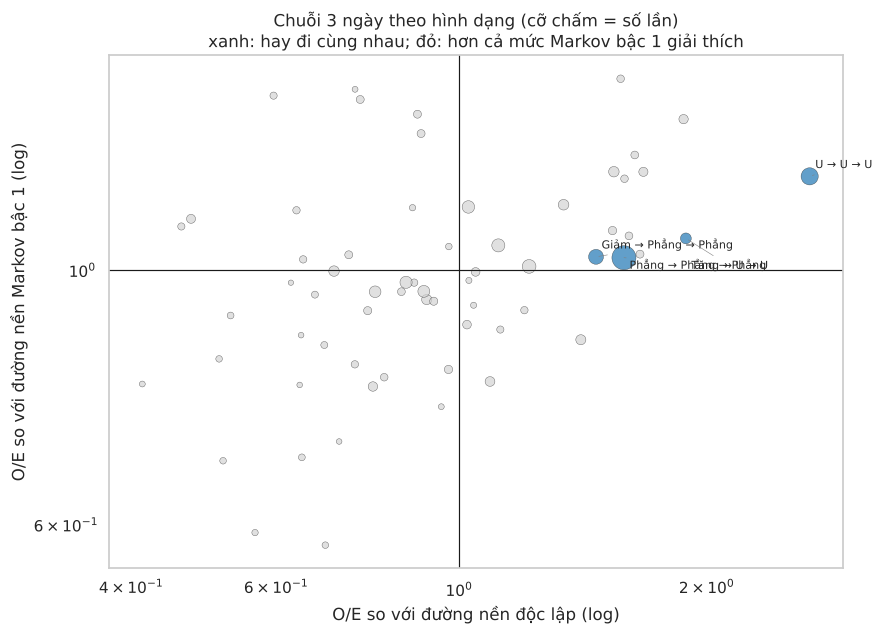

In [13]:
# Hình: mẫu 3 ngày theo hình dạng: O/E so với độc lập (trục x) và so với Markov (trục y)
g = PAT[(PAT["bang"] == "shape") & (PAT["L"] == 3)].copy()
g["lbl"] = g["mau"].map(lambda m: " → ".join(SHORT[x] for x in m.split(" → ")))
fig, ax = plt.subplots(figsize=(9, 6.5))
sigm = (g["q_Markov"] < 0.05) & (g["O/E_Markov"] >= 1.2)
sigi = (g["q_độc lập"] < 0.05) & (g["O/E_độc lập"] >= 1.3)
ax.scatter(g["O/E_độc lập"], g["O/E_Markov"], s=g["O"] * 1.5, c=np.where(sigm, "tab:red", np.where(sigi, "tab:blue", "lightgray")), alpha=.7, edgecolor="k", lw=.3)
for k, (_, r) in enumerate(g[sigi | sigm].sort_values("O/E_độc lập").iterrows()):
    ax.annotate(r["lbl"], (r["O/E_độc lập"], r["O/E_Markov"]), fontsize=8, xytext=(4, 6 - 14 * (k % 3)), textcoords="offset points",
                arrowprops=dict(arrowstyle="-", lw=.4, color="gray"))
ax.axhline(1, color="k", lw=.8); ax.axvline(1, color="k", lw=.8); ax.set_xscale("log"); ax.set_yscale("log")
ax.set(xlabel="O/E so với đường nền độc lập (log)", ylabel="O/E so với đường nền Markov bậc 1 (log)",
       title="Chuỗi 3 ngày theo hình dạng (cỡ chấm = số lần)\nxanh: hay đi cùng nhau; đỏ: hơn cả mức Markov bậc 1 giải thích")
plt.tight_layout(); plt.savefig(REPORT / "43_patterns_L3.png"); plt.show()

**Đọc kết quả (mining):**
- So với **đường nền độc lập**, có nhiều chuỗi lặp lại hơn ngẫu nhiên, nhưng phần lớn là **tự lặp lại**: `U → U → U` gấp 2,7 lần, `U → U → U → U` gấp 4,6 lần (gần như chỉ ở mùa Thu), `Phẳng → Phẳng → Phẳng` gấp 1,6 lần. Trên 12 kiểu ngày, `U|cao → U|cao → U|cao` xuất hiện 55 lần so với 7 lần kỳ vọng.
- Các chuỗi "có cốt truyện" cũng vượt đường nền độc lập: `Tăng → U → U` (1,9 lần), `Tăng → U → Giảm → Phẳng` (2,5 lần, 13 lần xuất hiện), `Tăng|TB → U|cao → U|cao` (3,4 lần).
- **Không chuỗi nào vượt đường nền Markov bậc 1** sau hiệu chỉnh BH (O/E_Markov từ 1,0 đến 1,6, q ≥ 0,28). Khớp với mục 3: các chuỗi dài là cặp chuyển nối nhau, không phải "kịch bản" riêng.
- Vì sao vẫn đáng tìm: cách đếm này cho biết chuỗi nào **xảy ra thường xuyên trên thực tế** (đó là điều người đọc quan tâm), còn đường nền Markov cho biết ta **không cần** giả thuyết nào phức tạp hơn để giải thích chúng.

## 5. Chuỗi mở và khép một đợt ô nhiễm (analysis + mining với PrefixSpan)

**Đợt ô nhiễm** (định nghĩa của notebook): một chuỗi tối đa các ngày liền nhau ở bậc `cao` (> 50 µg/m³, ngưỡng QCVN 05:2023 dùng từ đầu dự án). Một đợt chỉ được dùng để xem *mở* và *khép* khi **ngày trước và ngày sau đợt đều có nhãn** (nếu không, ta không biết đợt bắt đầu hay kết thúc thế nào: dữ liệu bị cắt, *censored*).

Lựa chọn khác: đợt theo phần dư thời tiết (`z ≥ 1,5` ở notebook 06), hoặc theo ngưỡng tương đối trong mùa (ví dụ trên P75 của tháng). Ngưỡng tuyệt đối dễ hiểu và gắn với quy chuẩn, nhưng gần như không có đợt vào mùa Hè.

**5a (analysis):** hình dạng ở ngày trước đợt (−1), ngày đầu, ngày cuối và ngày sau đợt (+1), so với tỷ lệ của cùng mùa.

In [14]:
def make_episodes(high):
    # high: Series bool theo ngày (ngày "cao"); đợt = chuỗi tối đa các ngày cao liền nhau trong một đoạn liên tục
    E = []
    for sid, g in S.dropna(subset=["seg"]).groupby("seg"):
        hi = high.reindex(g.index).fillna(False).values.astype(bool)
        r = (pd.Series(hi) != pd.Series(hi).shift()).cumsum().values
        for k in np.unique(r[hi]):
            m = np.where(r == k)[0]; i0, i1 = m[0], m[-1]
            before = g.iloc[i0 - 1] if i0 > 0 else None; after = g.iloc[i1 + 1] if i1 + 1 < len(g) else None
            E.append(dict(start=g.index[i0], end=g.index[i1], n_days=len(m), season=g["season"].iloc[i0], year=g.index[i0].year,
                          complete=before is not None and after is not None,
                          near_fault=bool(g["near_fault"].iloc[max(i0 - 1, 0): i1 + 2].any()),
                          pm25_peak=g["pm25_mean"].iloc[m].max(),
                          seq_shape=" ".join(g["shape"].iloc[max(i0 - 1, 0): i1 + 2]),
                          seq_daytype=" ".join(g["day_type"].iloc[max(i0 - 1, 0): i1 + 2]),
                          sh_before=before["shape"] if before is not None else None, sh_first=g["shape"].iloc[i0],
                          sh_last=g["shape"].iloc[i1], sh_after=after["shape"] if after is not None else None,
                          lv_after=after["level"] if after is not None else None))
    return pd.DataFrame(E)

EP = make_episodes(S["level"] == "cao")
EP.to_csv(OUT / "episodes.csv", index=False)
EC = EP[EP["complete"]].copy()
print(f"đợt (chuỗi ngày cao): {len(EP)} | đầy đủ hai đầu: {len(EC)} | bị cắt: {(~EP['complete']).sum()}")
print("đợt đầy đủ theo mùa:", EC["season"].value_counts().reindex(SEASONS, fill_value=0).to_dict())
print("độ dài đợt đầy đủ (ngày):", EC["n_days"].describe()[["50%", "mean", "max"]].to_dict(), "| 1 ngày:", (EC["n_days"] == 1).mean().round(2))
print("so sánh độ dài: đợt đầy đủ", EC["n_days"].mean().round(2), "| đợt bị cắt", EP.loc[~EP["complete"], "n_days"].mean().round(2))

đợt (chuỗi ngày cao): 230 | đầy đủ hai đầu: 139 | bị cắt: 91
đợt đầy đủ theo mùa: {'Đông': 46, 'Xuân': 25, 'Hè': 34, 'Thu': 34}
độ dài đợt đầy đủ (ngày): {'50%': 2.0, 'mean': 3.158273381294964, 'max': 17.0} | 1 ngày: 0.36
so sánh độ dài: đợt đầy đủ 3.16 | đợt bị cắt 2.87


vi_tri    ngày trước (−1)  ngày đầu  ngày cuối  ngày sau (+1)
shape                                                        
S1_U                 1.05      1.11       0.47           0.87
S2_tang              2.51      0.99       0.23           1.03
S3_giam              0.31      1.03       2.48           1.14
S4_phang             0.56      0.92       1.00           1.00

q-value:
vi_tri    ngày trước (−1)  ngày đầu  ngày cuối  ngày sau (+1)
shape                                                        
S1_U                  1.0     0.786        0.0          0.786
S2_tang               0.0     1.000        0.0          1.000
S3_giam               0.0     1.000        0.0          0.786
S4_phang              0.0     0.786        1.0          1.000


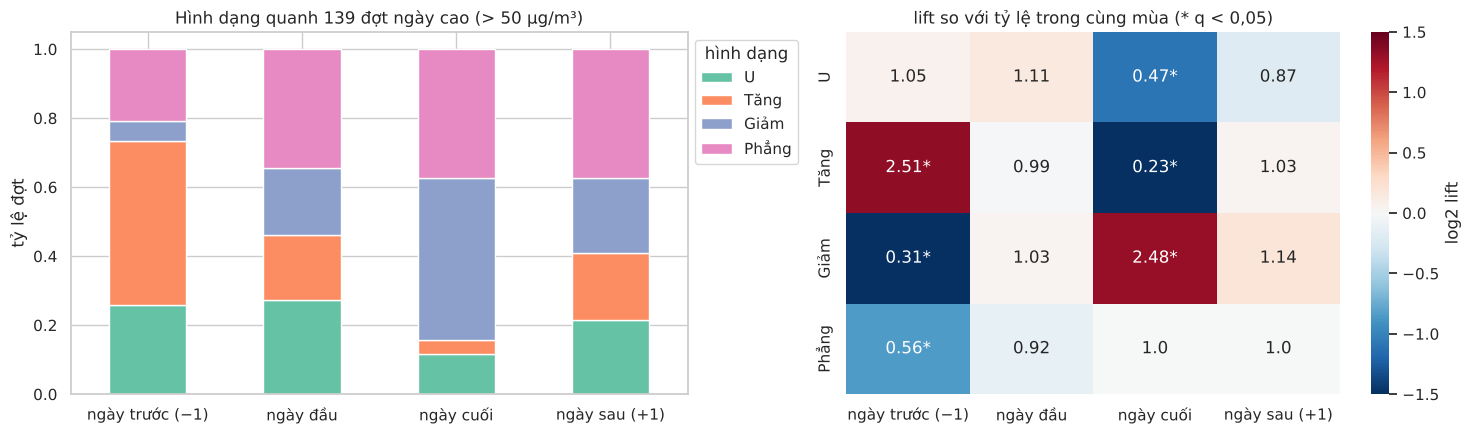

In [15]:
# Tỷ lệ hình dạng theo mùa làm đường nền; lift = tỷ lệ ở vị trí đó / tỷ lệ trong mùa (lấy trung bình có trọng số theo mùa của đợt)
base = S[S["present"]].groupby("season")["shape"].value_counts(normalize=True).unstack()[SHAPES]
pos_cols = {"sh_before": "ngày trước (−1)", "sh_first": "ngày đầu", "sh_last": "ngày cuối", "sh_after": "ngày sau (+1)"}
rows = []
for c, lab in pos_cols.items():
    for sh in SHAPES:
        obs = (EC[c] == sh).mean(); exp = EC["season"].map(base[sh]).mean()
        k = int((EC[c] == sh).sum()); p = stats.binomtest(k, len(EC), exp).pvalue
        rows.append(dict(vi_tri=lab, shape=sh, ty_le=obs, ky_vong=exp, lift=obs / exp, n=k, p=p))
POS = pd.DataFrame(rows); POS["q"] = bh(POS["p"])
print(POS.pivot(index="shape", columns="vi_tri", values="lift")[list(pos_cols.values())].round(2))
print("\nq-value:"); print(POS.pivot(index="shape", columns="vi_tri", values="q")[list(pos_cols.values())].round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
pv = POS.pivot(index="vi_tri", columns="shape", values="ty_le").reindex(list(pos_cols.values()))[SHAPES]
pv.columns = [SHORT[x] for x in SHAPES]
pv.plot(kind="bar", stacked=True, ax=ax[0], color=sns.color_palette("Set2", 4), rot=0)
ax[0].set(ylabel="tỷ lệ đợt", title=f"Hình dạng quanh {len(EC)} đợt ngày cao (> 50 µg/m³)", xlabel=""); ax[0].legend(title="hình dạng", bbox_to_anchor=(1, 1))
L = POS.pivot(index="shape", columns="vi_tri", values="lift").reindex(SHAPES)[list(pos_cols.values())]
Q = POS.pivot(index="shape", columns="vi_tri", values="q").reindex(SHAPES)[list(pos_cols.values())]
sns.heatmap(np.log2(L), ax=ax[1], cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5, annot=L.round(2).astype(str) + Q.map(lambda q: "*" if q < 0.05 else ""), fmt="",
            yticklabels=[SHORT[x] for x in SHAPES], cbar_kws={"label": "log2 lift"})
ax[1].set(title="lift so với tỷ lệ trong cùng mùa (* q < 0,05)", xlabel="", ylabel="")
plt.tight_layout(); plt.savefig(REPORT / "44_episode_open_close.png"); plt.show()

**Đọc kết quả (analysis):** đây là kết quả rõ nhất của notebook.
- **Mở đợt:** ngày ngay trước ngày cao đầu tiên là `Tăng` trong **47%** số đợt, gấp 2,5 lần tỷ lệ bình thường trong mùa (Đông 63%, Thu 47%, Xuân 44%, Hè 29%). Ngày trước đợt rất hiếm khi là `Giảm` (6%, lift 0,31).
- **Khép đợt:** ngày cao **cuối cùng** là `Giảm` trong **47%** số đợt (lift 2,5), rất hiếm khi là `Tăng` (4%, lift 0,23).
- **Ngày đầu đợt và ngày sau đợt không khác bình thường** (lift 0,9–1,1). Nghĩa là "điểm đánh dấu" nằm ở hai mép của đợt, còn ở giữa thì hình dạng nào cũng có thể (`U`, `Phẳng`, ...). Ngày sau đợt gần như luôn là `TB` (93%), hiếm khi xuống thẳng `thấp`.
- **Diễn giải cẩn trọng:** hình dạng được tính trong từng ngày lịch (0–23 giờ). Một đợt bắt đầu vào buổi tối sẽ tự làm ngày hôm đó có dạng `Tăng` và ngày hôm sau có mức cao; một đợt tan trong ban ngày sẽ làm ngày cuối có dạng `Giảm`. Vì vậy kết quả này chủ yếu nói về **thời điểm**: đợt ô nhiễm ở trạm này thường **bắt đầu vào buổi tối/ban đêm và kết thúc trong ban ngày**. Điều đó khớp với notebook 05 (ngày `Tăng` đi kèm gió giảm về tối, ngày `Giảm` đi kèm gió tăng về tối), nhưng vẫn là mối liên hệ, không chứng minh gió là nguyên nhân.

**5b (mining): PrefixSpan trên cơ sở dữ liệu các đợt.** Mỗi đợt đầy đủ là một chuỗi kiểu ngày (hình dạng|mức) từ ngày −1 đến ngày +1. PrefixSpan tìm các **chuỗi con** (giữ thứ tự, *cho phép cách quãng*) xuất hiện trong ít nhất `min_support` đợt. Ý tưởng của PrefixSpan: thay vì sinh mọi ứng viên như GSP, nó lấy từng tiền tố phổ biến rồi chỉ tìm tiếp trong phần đuôi của các chuỗi chứa tiền tố đó (*projected database*), nên không phải quét lại toàn bộ dữ liệu.

Một chuỗi phổ biến trong các đợt chưa chắc **đặc trưng** cho đợt: `TB → cao` đương nhiên có ở mọi đợt mở bằng ngày TB. Vì vậy ta so với **cơ sở dữ liệu đối chứng**: với mỗi đợt, lấy 10 cửa sổ ngẫu nhiên có cùng độ dài, cùng mùa, từ các đoạn liên tục. Mẫu đặc trưng = support trong đợt cao gấp ≥ 1,5 lần support trong đối chứng, Fisher + BH (đây là *contrast / discriminative pattern mining*).

In [16]:
def prefixspan(db, min_sup, max_len=4):
    # db: list các chuỗi (list ký hiệu). Trả về {mẫu (tuple): số chuỗi chứa mẫu}
    res = {}
    def grow(prefix, proj):
        # proj: list (id chuỗi, vị trí bắt đầu tìm tiếp)
        cnt = defaultdict(set)
        for sid, st in proj:
            for x in set(db[sid][st:]):
                cnt[x].add(sid)
        for x, sids in cnt.items():
            if len(sids) < min_sup: continue
            p = prefix + (x,); res[p] = len(sids)
            if len(p) < max_len:
                nproj = []
                for sid, st in proj:
                    s = db[sid]
                    for j in range(st, len(s)):
                        if s[j] == x: nproj.append((sid, j + 1)); break
                grow(p, nproj)
    grow((), [(i, 0) for i in range(len(db))])
    return res

def contains(seq, pat):
    it = iter(seq); return all(any(x == p for x in it) for p in pat)

def contains_contig(seq, pat):
    L = len(pat); return any(tuple(seq[i:i + L]) == tuple(pat) for i in range(len(seq) - L + 1))

db_ep = [s.split(" ") for s in EC["seq_daytype"]]
# Cơ sở dữ liệu đối chứng: cửa sổ ngẫu nhiên cùng độ dài, cùng mùa
pool = {}
for L in sorted(set(len(s) for s in db_ep)):
    W = windows("day_type", L); pool[L] = W
db_ctl = []
r = np.random.default_rng(SEED)
for s, se in zip(db_ep, EC["season"]):
    W = pool[len(s)]; W = W[W["season"] == se]
    for i in r.choice(len(W), size=min(10, len(W)), replace=False):
        db_ctl.append(list(W.iloc[i][[f"x{j}" for j in range(len(s))]]))
MINSUP = max(5, int(0.10 * len(db_ep)))
fp = prefixspan(db_ep, MINSUP, max_len=4)
rows = []
for pat, sup in fp.items():
    if len(pat) < 2: continue
    c_ctl = sum(contains(s, pat) for s in db_ctl)
    sup_e, sup_c = sup / len(db_ep), c_ctl / len(db_ctl)
    p = stats.fisher_exact([[sup, len(db_ep) - sup], [c_ctl, len(db_ctl) - c_ctl]], alternative="greater")[1]
    rows.append(dict(mau=" → ".join(pat), L=len(pat), sup_dot=sup_e, sup_doi_chung=sup_c, ratio=sup_e / max(sup_c, 1e-9),
                     lien_nhau=sum(contains_contig(s, pat) for s in db_ep) / len(db_ep), p=p))
EPP = pd.DataFrame(rows); EPP["q"] = bh(EPP["p"])
EPP.to_csv(OUT / "episode_patterns.csv", index=False)
print(f"đợt: {len(db_ep)} | đối chứng: {len(db_ctl)} | min_support = {MINSUP} đợt | mẫu phổ biến (L ≥ 2): {len(EPP)}")
disc = EPP[(EPP["ratio"] >= 1.5) & (EPP["q"] < 0.05)].sort_values(["sup_dot"], ascending=False)
print(f"mẫu đặc trưng cho đợt: {len(disc)}")
print(disc.head(25).round(3).to_string(index=False))

đợt: 139 | đối chứng: 1390 | min_support = 13 đợt | mẫu phổ biến (L ≥ 2): 49
mẫu đặc trưng cho đợt: 36
                                      mau  L  sup_dot  sup_doi_chung  ratio  lien_nhau     p     q
                 S2_tang|TB → S3_giam|cao  2    0.288          0.088  3.252      0.058 0.000 0.000
                   S1_U|cao → S3_giam|cao  2    0.281          0.150  1.875      0.216 0.000 0.001
                S2_tang|TB → S4_phang|cao  2    0.266          0.117  2.270      0.173 0.000 0.000
                S3_giam|cao → S4_phang|TB  2    0.237          0.125  1.897      0.173 0.000 0.002
               S4_phang|cao → S3_giam|cao  2    0.230          0.123  1.871      0.158 0.001 0.002
               S4_phang|cao → S4_phang|TB  2    0.230          0.132  1.739      0.173 0.002 0.006
                S3_giam|cao → S3_giam|cao  2    0.187          0.097  1.926      0.101 0.002 0.005
                    S2_tang|TB → S1_U|cao  2    0.187          0.101  1.844      0.144 0.003 0.007
      

In [17]:
# Chỉ xem phần mở và khép: 2 ngày đầu (−1, ngày đầu) và 2 ngày cuối (ngày cuối, +1), theo hình dạng
op = (EC["sh_before"].map(SHORT) + " → " + EC["sh_first"].map(SHORT)).value_counts()
cl_ = (EC["sh_last"].map(SHORT) + " → " + EC["sh_after"].map(SHORT)).value_counts()
full = (EC["sh_before"].map(SHORT) + " → [" + EC["sh_first"].map(SHORT) + " … " + EC["sh_last"].map(SHORT) + "] → " + EC["sh_after"].map(SHORT)).value_counts()
print("Mở đợt (ngày −1 → ngày đầu):"); print((op / len(EC)).head(6).round(2).to_string())
print("\nKhép đợt (ngày cuối → ngày +1):"); print((cl_ / len(EC)).head(6).round(2).to_string())
print("\nKhung đợt phổ biến nhất (−1 → [đầu … cuối] → +1):"); print(full.head(8).to_string())
print("\nMức ngày sau đợt:", EC["lv_after"].value_counts(normalize=True).round(2).to_dict())

Mở đợt (ngày −1 → ngày đầu):
Tăng → Phẳng     0.17
Tăng → U         0.14
U → U            0.11
Phẳng → Phẳng    0.10
Tăng → Tăng      0.10
Phẳng → Giảm     0.06

Khép đợt (ngày cuối → ngày +1):
Giảm → Phẳng     0.18
Phẳng → Phẳng    0.17
Giảm → Tăng      0.12
Giảm → U         0.09
Giảm → Giảm      0.09
Phẳng → Giảm     0.09

Khung đợt phổ biến nhất (−1 → [đầu … cuối] → +1):
Tăng → [Phẳng … Phẳng] → Giảm      6
Tăng → [Phẳng … Giảm] → Phẳng      5
Tăng → [Giảm … Giảm] → Phẳng       5
Phẳng → [Phẳng … Phẳng] → Phẳng    4
Phẳng → [Phẳng … Phẳng] → Giảm     4
Phẳng → [Giảm … Giảm] → Phẳng      4
Tăng → [Phẳng … Phẳng] → Phẳng     4
U → [Giảm … Giảm] → Phẳng          3

Mức ngày sau đợt: {'TB': 0.93, 'thấp': 0.07}


**Đọc kết quả (mining):**
- Mẫu đặc trưng mạnh nhất là `Tăng|TB → … → Giảm|cao`: có trong **29%** số đợt so với 9% cửa sổ đối chứng (gấp 3,3 lần). Nhưng chỉ 6% đợt có hai ngày này **liền nhau**: giữa chúng thường có một hay nhiều ngày cao khác. Đây chính là lý do dùng PrefixSpan (cho phép cách quãng) thay vì chỉ đếm chuỗi liền nhau.
- Chuỗi ví dụ trong câu hỏi, `Tăng|TB → U|cao → Giảm|cao`, có trong **14%** số đợt so với 4% đối chứng (gấp 3,2 lần). Phiên bản với ngày giữa `Phẳng|cao` phổ biến tương đương (15% so với 3%, gấp 5,3 lần).
- Không có "khung" nào chiếm ưu thế: khung phổ biến nhất (`Tăng → [Phẳng … Phẳng] → Giảm`) chỉ có 6 trên 139 đợt. Cách mô tả đúng hơn là **một khuôn mở/khép chung, với phần giữa thay đổi**, không phải một chuỗi cố định lặp lại.
- Giới hạn: support tính trên 139 đợt; mẫu có support 10–15% chỉ dựa trên 14–20 đợt. Cửa sổ đối chứng lấy ngẫu nhiên nên số liệu đổi nhẹ theo `SEED`.

## 6. Độ vững theo năm, theo mùa và khi bỏ ngày cạnh lỗi đo (analysis)

Dùng cùng tinh thần với notebook 05: một mẫu chỉ được coi là **vững** nếu
1. **Theo năm:** O/E > 1 ở ≥ 75% số năm có E ≥ 2 (cần ≥ 4 năm như vậy).
2. **Holdout theo thời gian:** ước lượng tỷ lệ và ma trận chuyển chỉ trên 2016–2020, rồi đếm và mô phỏng trên 2021–2025: O/E > 1,1.
3. **Theo mùa:** báo cáo số mùa có O/E > 1 (trong các mùa có E ≥ 3). Một mẫu chỉ có ở một mùa không sai, nhưng phải nói rõ.
4. **Bỏ ngày cạnh lỗi đo:** O/E gần như không đổi.

Áp dụng cho: cặp chuyển hình dạng nổi bật (mục 2) và các chuỗi 3–4 ngày theo hình dạng vượt đường nền độc lập (mục 4).

In [18]:
def per_group_OE(col, states, pats, sims, group_fn, L_list, day_mask=None):
    # O/E so với đường nền 'ind' và 'mk' theo nhóm (năm hoặc mùa) cho danh sách mẫu
    K = len(states); ix = {s: i for i, s in enumerate(states)}
    obs = S[col].map(ix).fillna(-1).astype(int).values; out = []
    for L in L_list:
        W = windows(col, L)
        if day_mask is not None: W = W[day_mask(W)]
        starts = S.index.get_indexer(W["date"]); grp = group_fn(W).values
        o = count_codes(obs, starts, L, K)[0]; es = {k: count_codes(sims[k], starts, L, K) for k in sims}
        for pat in [p for p in pats if len(p.split(" → ")) == L]:
            c = 0
            for x in pat.split(" → "): c = c * K + ix[x]
            for gv in np.unique(grp):
                m = grp == gv
                d = dict(mau=pat, nhom=gv, O=int((o[m] == c).sum()))
                for k in sims: d[f"E_{k}"] = (es[k][:, m] == c).sum(1).mean()
                out.append(d)
    return pd.DataFrame(out)

pair_sig = sig[sig["bang"] == "shape"]
pats2 = sorted(set(pair_sig["tu"] + " → " + pair_sig["den"]))
pats34 = PAT[(PAT["bang"] == "shape") & (PAT["L"] >= 3) & (PAT["q_độc lập"] < 0.05) & (PAT["O/E_độc lập"] >= 1.3)]["mau"].tolist()
cand = pats2 + pats34
YR = per_group_OE("shape", SHAPES, cand, SIM_shape, lambda W: W["year"], [2, 3, 4])
SE = per_group_OE("shape", SHAPES, cand, SIM_shape, lambda W: W["season"], [2, 3, 4])

def robust_year(g, k):
    g = g[g[f"E_{k}"] >= 2]; ratio = g["O"] / g[f"E_{k}"]
    return pd.Series({"so_nam": len(g), "ty_le_nam_OE>1": (ratio > 1).mean() if len(g) else np.nan})
ry = YR.groupby("mau").apply(lambda g: robust_year(g, "ind"), include_groups=False)
rs = SE.groupby("mau").apply(lambda g: pd.Series({"mua_OE>1": ", ".join(g.loc[(g["E_ind"] >= 3) & (g["O"] > g["E_ind"]), "nhom"]),
                                                    "so_mua_xet": int((g["E_ind"] >= 3).sum())}), include_groups=False)
ry_mk = YR.groupby("mau").apply(lambda g: robust_year(g, "mk"), include_groups=False).add_suffix("_Markov")

In [19]:
# Holdout: tham số từ 2016–2020, đánh giá trên 2021–2025
train_mask = S["year"] <= 2020
PAR_tr = fit_params("shape", SHAPES, train_mask)
SIM_tr = {k: simulate("shape", SHAPES, PAR_tr, k, seed=SEED + 1) for k in ["ind", "mk"]}
HO = per_group_OE("shape", SHAPES, cand, SIM_tr, lambda W: pd.Series(np.where(W["year"] >= 2021, "2021–25", "2016–20")), [2, 3, 4])
HO = HO[HO["nhom"] == "2021–25"].set_index("mau")
# Bỏ ngày cạnh lỗi đo: chỉ đếm cửa sổ không chứa ngày cạnh lỗi đo (mô phỏng dùng lại, cùng tập cửa sổ)
NF = per_group_OE("shape", SHAPES, cand, SIM_shape, lambda W: pd.Series(["all"] * len(W)), [2, 3, 4], day_mask=lambda W: ~W["near_fault"])
NF = NF.set_index("mau")

R = PAT[(PAT["bang"] == "shape") & PAT["mau"].isin(cand)].set_index("mau")[["L", "O", "O/E_độc lập", "q_độc lập", "O/E_Markov", "q_Markov"]]
R = R.join(ry).join(ry_mk[["ty_le_nam_OE>1_Markov"]]).join(rs)
R["OE_holdout"] = HO["O"] / HO["E_ind"]
R["OE_holdout_Markov"] = HO["O"] / HO["E_mk"]
R["OE_bo_canh_loi"] = NF["O"] / NF["E_ind"]
R["vung"] = (R["so_nam"] >= 4) & (R["ty_le_nam_OE>1"] >= 0.75) & (R["OE_holdout"] > 1.1)
R["vung_Markov"] = (R["L"] >= 3) & (R["ty_le_nam_OE>1_Markov"] >= 0.75) & (R["OE_holdout_Markov"] > 1.1) & (R["q_Markov"] < 0.05)
R.index = [" → ".join(SHORT[x] for x in m.split(" → ")) for m in R.index]
R = R.sort_values(["L", "O/E_độc lập"], ascending=[True, False])
R.to_csv(OUT / "seq_patterns_robust.csv")
pd.set_option("display.max_colwidth", 30)
print(R.round(2).to_string())
print(f"\nvững (so với độc lập): {int(R['vung'].sum())}/{len(R)} | vững cả so với Markov (L ≥ 3): {int(R['vung_Markov'].sum())}")

                               L    O  O/E_độc lập  q_độc lập  O/E_Markov  q_Markov  so_nam  ty_le_nam_OE>1  ty_le_nam_OE>1_Markov             mua_OE>1  so_mua_xet  OE_holdout  OE_holdout_Markov  OE_bo_canh_loi   vung  vung_Markov
U → U                          2  204         1.53       0.01        1.01      0.57    10.0            0.80                   0.60  Hè, Thu, Xuân, Đông           4        1.26               0.85            1.52   True        False
Phẳng → Phẳng                  2  406         1.27       0.01        1.01      0.57    10.0            0.80                   0.50  Hè, Thu, Xuân, Đông           4        1.37               1.07            1.28   True        False
Tăng → Tăng                    2   90         1.24       0.18        1.00      0.57    10.0            0.70                   0.50  Hè, Thu, Xuân, Đông           4        1.38               1.05            1.24  False        False
Giảm → Giảm                    2   88         1.20       0.19        1.00   

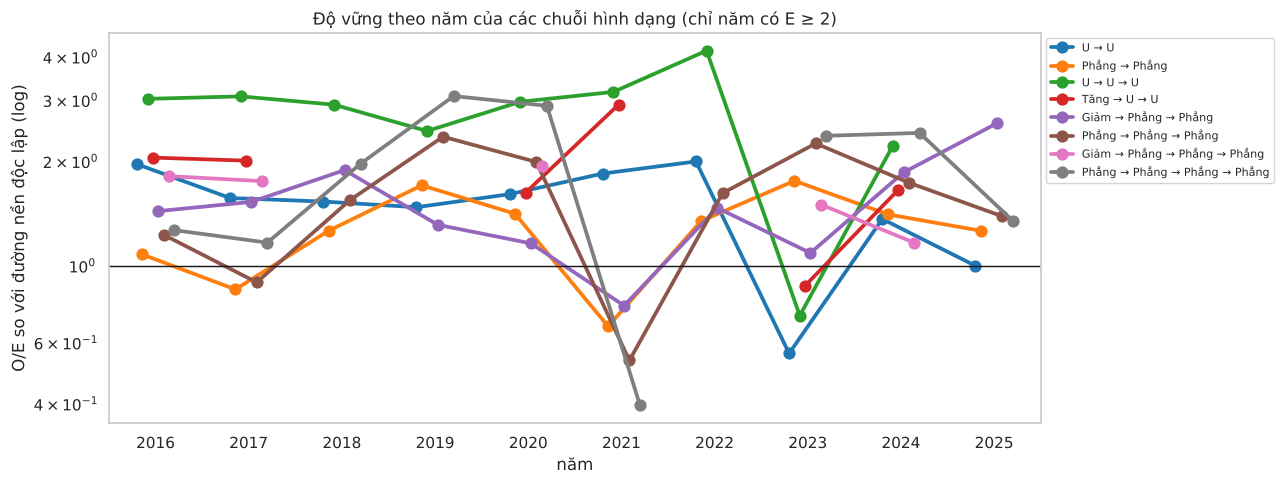

In [20]:
# Hình: O/E theo năm cho các mẫu vững dài ≥ 3 ngày và vài cặp chuyển chính
top = R[R["vung"]].sort_values("O", ascending=False)
show = list(top[top["L"] == 2].index[:4]) + list(top[top["L"] >= 3].index[:6])
inv = {" → ".join(SHORT[x] for x in m.split(" → ")): m for m in cand}
Y = YR[YR["mau"].isin([inv[s] for s in show]) & (YR["E_ind"] >= 2)].copy()
Y["OE"] = Y["O"] / Y["E_ind"]; Y["lbl"] = Y["mau"].map(lambda m: " → ".join(SHORT[x] for x in m.split(" → ")))
fig, ax = plt.subplots(figsize=(13, 5))
sns.pointplot(data=Y, x="nhom", y="OE", hue="lbl", ax=ax, dodge=0.4, markers="o", linestyles="-", palette="tab10")
ax.axhline(1, color="k", lw=1); ax.set_yscale("log")
ax.set(xlabel="năm", ylabel="O/E so với đường nền độc lập (log)", title="Độ vững theo năm của các chuỗi hình dạng (chỉ năm có E ≥ 2)")
ax.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.savefig(REPORT / "45_robust_by_year.png"); plt.show()

**Độ vững của khung mở/khép đợt.** Kết quả mạnh nhất của notebook nằm ở mục 5 (ngày trước đợt hay là `Tăng`, ngày cuối đợt hay là `Giảm`), nên kiểm tra kỹ hơn:
- theo năm (năm có ≥ 5 đợt đầy đủ) và theo mùa;
- holdout: tỷ lệ nền theo mùa lấy từ 2016–2020, đợt lấy từ 2021–2025;
- bỏ các đợt chạm ngày cạnh lỗi đo; bỏ đợt chỉ 1 ngày;
- **định nghĩa đợt khác:** ngày "cao" = trên P75 của PM2.5 trung bình ngày **trong cùng tháng** (ngưỡng tương đối, có cả đợt mùa Hè), và đợt theo phần dư thời tiết của notebook 06 (z ≥ 1,5).

                               Tăng ở ngày −1  Giảm ở ngày cuối  Giảm ở ngày −1  Tăng ở ngày cuối  số đợt
tất cả                                   2.51              2.48            0.31              0.23   139.0
mùa Đông                                 2.63              2.23            0.00              0.18    46.0
mùa Xuân                                 2.61              3.50            0.54              0.00    25.0
mùa Hè                                   1.72              2.59            0.76              0.34    34.0
mùa Thu                                  3.08              2.16            0.14              0.39    34.0
holdout 2021–25 (nền 2016–20)            3.04              2.14            0.34              0.35    63.0
bỏ đợt cạnh lỗi đo                       2.52              2.44            0.31              0.23   137.0
chỉ đợt ≥ 2 ngày                         2.58              2.98            0.18              0.06    89.0
định nghĩa: > P75 của tháng              1.51 

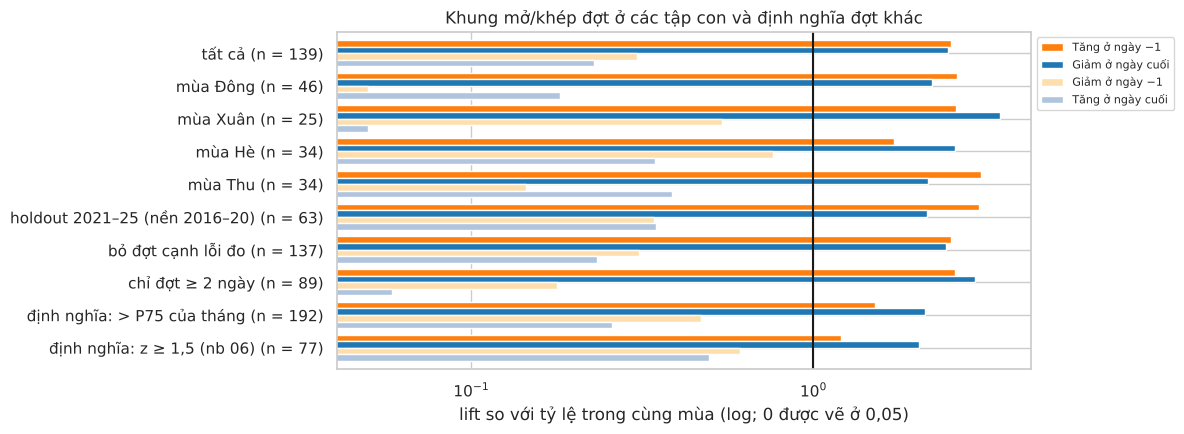

In [21]:
def boundary_lift(ec, base_tbl):
    out = {}
    for c, sh, lab in [("sh_before", "S2_tang", "Tăng ở ngày −1"), ("sh_last", "S3_giam", "Giảm ở ngày cuối"),
                       ("sh_before", "S3_giam", "Giảm ở ngày −1"), ("sh_last", "S2_tang", "Tăng ở ngày cuối")]:
        exp = ec["season"].map(base_tbl[sh]).mean()
        out[lab] = (ec[c] == sh).mean() / exp if len(ec) else np.nan
    out["số đợt"] = len(ec)
    return pd.Series(out)

rows = {"tất cả": boundary_lift(EC, base)}
for s in SEASONS:
    rows[f"mùa {s}"] = boundary_lift(EC[EC["season"] == s], base)
base_tr = S[S["present"] & (S["year"] <= 2020)].groupby("season")["shape"].value_counts(normalize=True).unstack()[SHAPES]
rows["holdout 2021–25 (nền 2016–20)"] = boundary_lift(EC[EC["year"] >= 2021], base_tr)
rows["bỏ đợt cạnh lỗi đo"] = boundary_lift(EC[~EC["near_fault"]], base)
rows["chỉ đợt ≥ 2 ngày"] = boundary_lift(EC[EC["n_days"] >= 2], base)
# Định nghĩa khác 1: trên P75 của tháng (theo từng tháng lịch, gộp các năm)
p75 = S[S["present"]].groupby(S.index[S["present"]].month)["pm25_mean"].quantile(0.75)
EP_rel = make_episodes(S["pm25_mean"] > S.index.month.map(p75).values)
rows["định nghĩa: > P75 của tháng"] = boundary_lift(EP_rel[EP_rel["complete"]], base)
# Định nghĩa khác 2: phần dư thời tiết notebook 06, z ≥ 1,5
EP_z = make_episodes(an["z"].reindex(S.index) >= 1.5)
rows["định nghĩa: z ≥ 1,5 (nb 06)"] = boundary_lift(EP_z[EP_z["complete"]], base)
RB = pd.DataFrame(rows).T
print(RB.round(2).to_string())

yr = EC.groupby("year").filter(lambda g: len(g) >= 5).groupby("year").apply(lambda g: boundary_lift(g, base), include_groups=False)
print("\nTheo năm (năm có ≥ 5 đợt đầy đủ):"); print(yr.round(2).to_string())
print("\nTỷ lệ năm có lift > 1:", {c: f"{(yr[c] > 1).mean():.0%}" for c in ["Tăng ở ngày −1", "Giảm ở ngày cuối"]},
      "| tỷ lệ năm có lift < 1:", {c: f"{(yr[c] < 1).mean():.0%}" for c in ["Giảm ở ngày −1", "Tăng ở ngày cuối"]})

fig, ax = plt.subplots(figsize=(12, 4.5))
pl = RB[["Tăng ở ngày −1", "Giảm ở ngày cuối", "Giảm ở ngày −1", "Tăng ở ngày cuối"]].clip(lower=0.05)
pl.plot(kind="barh", ax=ax, color=["tab:orange", "tab:blue", "navajowhite", "lightsteelblue"], width=.8)
ax.axvline(1, color="k"); ax.set_xscale("log"); ax.invert_yaxis()
ax.set(xlabel="lift so với tỷ lệ trong cùng mùa (log; 0 được vẽ ở 0,05)", title="Khung mở/khép đợt ở các tập con và định nghĩa đợt khác")
ax.set_yticklabels([f"{i} (n = {int(n)})" for i, n in zip(RB.index, RB["số đợt"])])
ax.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.savefig(REPORT / "47_episode_robust.png"); plt.show()

**Đọc kết quả:**
- **Chuỗi theo hình dạng (mục 4):** 8 trên 20 mẫu đạt tiêu chí vững so với đường nền độc lập, đều là chuỗi tự lặp lại hoặc dẫn vào chuỗi tự lặp lại (`U → U → U`, `Tăng → U → U`, `Giảm → Phẳng → Phẳng`, `Phẳng → Phẳng → …`). Các mẫu 4 ngày còn lại quá hiếm để kiểm tra theo năm (E < 2 mỗi năm), nên chỉ coi là gợi ý. **Không mẫu nào vững so với đường nền Markov.** Kết quả không đổi khi bỏ ngày cạnh lỗi đo.
- **Khung mở/khép đợt (mục 5) rất vững:** `Tăng` ở ngày trước đợt có lift > 1 ở 9/10 năm (năm 2016 là 0,98), `Giảm` ở ngày cuối đợt có lift > 1 ở 10/10 năm, và ở cả bốn mùa. Holdout 2021–2025 với tỷ lệ nền từ 2016–2020: lift 3,0 và 2,1. Bỏ đợt cạnh lỗi đo hay bỏ đợt 1 ngày đều không đổi.
- **Theo định nghĩa đợt khác:** phần **khép** bằng `Giảm` vẫn giữ (lift 2,0–2,1 với ngưỡng P75 của tháng và với phần dư thời tiết z ≥ 1,5). Phần **mở** bằng `Tăng` yếu đi (1,5 và 1,2). Với đợt định nghĩa bằng phần dư thời tiết, tức các ngày bẩn hơn mức thời tiết cho phép, đợt ít khi bắt đầu bằng một buổi tối tích tụ. Đây là một giả thuyết đáng kiểm tra tiếp (ví dụ với điểm cháy hay nguồn thải đột xuất), chưa phải kết luận.

## 7. Ví dụ một chuỗi trên đường cong theo giờ (analysis)

Để thấy các nhãn nghĩa là gì trên dữ liệu gốc: vẽ PM2.5 theo giờ của vài đợt đầy đủ có khung phổ biến nhất, kèm điểm cháy và gió theo ngày.

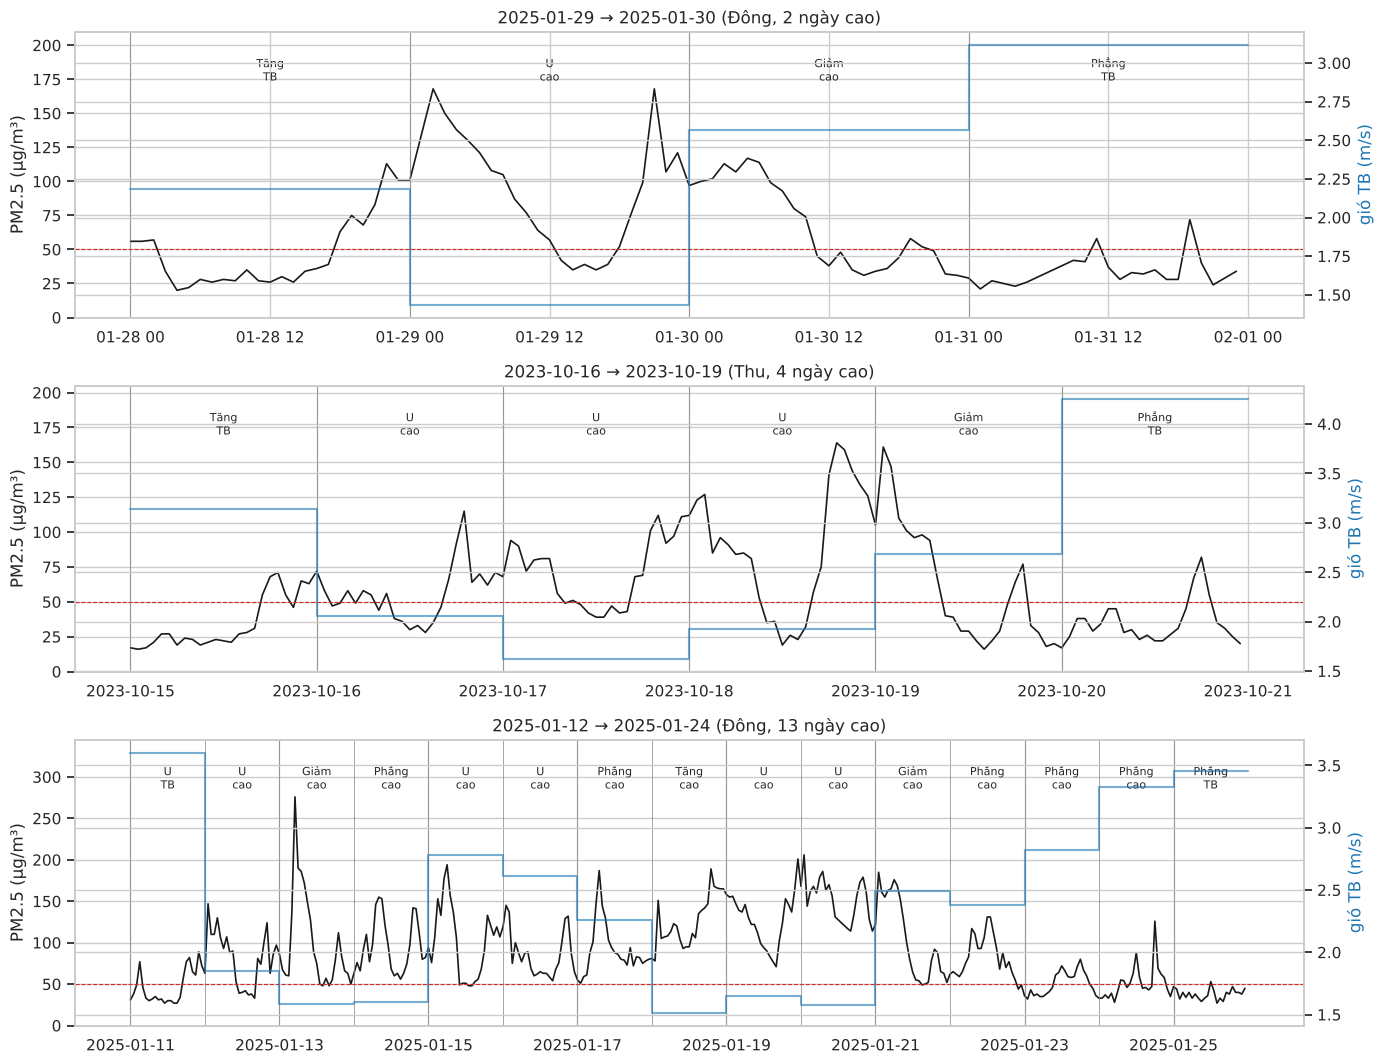

In [22]:
Dm = D.reindex(S.index)
def plot_episode(ax, row):
    d0, d1 = row["start"] - pd.Timedelta(days=1), row["end"] + pd.Timedelta(days=1)
    days = pd.date_range(d0, d1)
    y = np.concatenate([Dm.loc[d, HCOLS].values.astype(float) for d in days])
    x = pd.date_range(d0, periods=24 * len(days), freq="h")
    ax.plot(x, y, color="k", lw=1.2); ax.axhline(50, color="tab:red", ls="--", lw=.8)
    for d in days:
        ax.axvline(d, color="gray", lw=.5)
        ax.text(d + pd.Timedelta(hours=12), ax.get_ylim()[1] if False else np.nanmax(y) * 1.02, f"{SHORT[S.loc[d, 'shape']]}\n{S.loc[d, 'level']}", ha="center", va="bottom", fontsize=8)
    ax2 = ax.twinx(); wv = Dm.loc[days, "ws_mean"].values; ax2.step(list(days) + [d1 + pd.Timedelta(days=1)], list(wv) + [wv[-1]], where="post", color="tab:blue", alpha=.6); ax2.set_ylabel("gió TB (m/s)", color="tab:blue")
    ax.set(title=f"{row['start'].date()} → {row['end'].date()} ({row['season']}, {row['n_days']} ngày cao)", ylabel="PM2.5 (µg/m³)")
    ax.set_ylim(0, np.nanmax(y) * 1.25)

sel = EC.assign(k=EC["sh_before"].map(SHORT) + ">" + EC["sh_after"].map(SHORT))
topk = sel["k"].value_counts().index[0]
ex = pd.concat([sel[(sel["k"] == topk) & (sel["n_days"].between(2, 4))].sort_values("pm25_peak", ascending=False).head(2),
                sel[(sel["n_days"] >= 3)].sort_values("pm25_peak", ascending=False).head(1)])
fig, axes = plt.subplots(len(ex), 1, figsize=(14, 3.6 * len(ex)))
for ax, (_, row) in zip(np.atleast_1d(axes), ex.iterrows()):
    plot_episode(ax, row)
plt.tight_layout(); plt.savefig(REPORT / "46_episode_examples.png"); plt.show()

In [23]:
# Lưu chuỗi theo ngày cho các bước sau (dự báo ở Giai đoạn 4 có thể dùng 'shape_prev', 'level_prev')
out = S[["shape", "level", "day_type", "pm25_mean", "season", "year", "present", "suspect", "near_fault", "seg", "pos"]].copy()
out["shape_prev"] = S["shape"].shift(1).where(S["pos"] > 0)
out["level_prev"] = S["level"].shift(1).where(S["pos"] > 0)
ep_id = pd.Series(np.nan, index=S.index)
for i, r in EP.iterrows():
    ep_id.loc[r["start"]: r["end"]] = i
out["episode_id"] = ep_id
out.to_csv(OUT / "day_sequences.csv")
PAT.to_csv(OUT / "seq_patterns.csv", index=False)
print("đã lưu:", [p.name for p in OUT.glob("*") if p.name.startswith(("day_seq", "seq_", "episode", "transitions"))])

đã lưu: ['transitions_by_season.csv', 'episodes.csv', 'day_sequences.csv', 'episode_patterns.csv', 'seq_patterns.csv', 'seq_patterns_robust.csv']


## 8. Tóm tắt

**Loại công việc:** analysis (ma trận chuyển, khung mở/khép đợt), mining (episode mining kiểu WINEPI với đường nền mô phỏng, PrefixSpan trên cơ sở dữ liệu đợt, contrast với cửa sổ đối chứng), đánh giá kiểu ML (so sánh bậc Markov bằng log-loss ngoài mẫu theo năm).

**Kết quả chính:**
1. **Mức bền, hình dạng ít bền.** Ngày `cao` kéo theo ngày `cao` (78% ở Đông và Thu). Hình dạng chủ yếu tự lặp lại (`U` ở mùa Thu, `Phẳng` ở mùa Xuân); chuyển giữa các hình dạng yếu nếu không xét mức.
2. **Không có "trí nhớ" quá một ngày.** Markov bậc 2 không tốt hơn bậc 1 khi đánh giá ngoài mẫu, và không chuỗi 3–4 ngày nào vượt đường nền Markov bậc 1. Chuỗi dài = các cặp chuyển nối nhau.
3. **Đợt ô nhiễm có khuôn mở/khép rõ ràng:** ngày trước đợt thường là `Tăng` (47%, gấp 2,5 lần bình thường), ngày cao cuối thường là `Giảm` (47%, gấp 2,5 lần); phần giữa thay đổi. Chuỗi trong câu hỏi `Tăng|TB → U|cao → Giảm|cao` có trong 14% số đợt, gấp 3 lần đối chứng, nhưng **không phải chuỗi duy nhất**. Khuôn này vững qua 9–10/10 năm, cả bốn mùa và holdout 2021–2025.
4. **Diễn giải:** đợt ô nhiễm tại trạm này thường bắt đầu vào buổi tối/ban đêm và tan trong ban ngày, khớp với điều kiện gió tối của notebook 05. Đây là mối liên hệ theo thời gian, không phải nhân quả.

**Giới hạn:**
- Một trạm; 34% số ngày không có nhãn, độ phủ khác nhau nhiều giữa các năm; khoảng 40% đợt bị cắt ở ít nhất một đầu nên không dùng được để xem mở/khép.
- Hình dạng được tính theo ngày lịch, nên một phần của khuôn mở/khép là hệ quả của việc cắt chuỗi giờ lúc nửa đêm (xem mục 5a).
- Đợt định nghĩa theo ngưỡng tuyệt đối 50 µg/m³, gần như không có đợt mùa Hè. Với ngưỡng tương đối hay phần dư thời tiết, phần mở đợt yếu hơn.
- Ít dữ liệu cho mẫu dài: các chuỗi 4 ngày chỉ là gợi ý.

**Quyết định nên ghi vào "Nhật ký quyết định":**
- Ngày thiếu và ngày nghi lỗi đo **cắt chuỗi**, không điền nhãn, không nối qua khoảng trống; chuỗi gán theo mùa của ngày đầu. Ngày cạnh lỗi đo giữ lại, có kiểm tra độ nhạy.
- Đường nền so sánh: độc lập trong cùng mùa và Markov bậc 1 theo mùa, bằng mô phỏng Monte Carlo 1.000 lần trên đúng các đoạn đã quan sát; BH q < 0,05.
- Đợt ô nhiễm = chuỗi tối đa ngày `cao` (> 50 µg/m³); chỉ dùng đợt có ngày trước và sau quan sát được. PrefixSpan chạy trên cơ sở dữ liệu đợt (min_support 10% số đợt, tối đa 4 phần tử), so với 10 cửa sổ đối chứng cùng mùa, cùng độ dài.
- Tiêu chí vững giống notebook 05 (≥ 75% số năm, ≥ 4 năm, holdout 2021–25 > 1,1), cộng thêm hai định nghĩa đợt thay thế.

**Bước tiếp theo có thể làm:** dùng `shape_prev` / `level_prev` (đã lưu trong `data/day_sequences.csv`) làm biến cho Giai đoạn 4 (dự báo mức ngày mai); hoặc tính lại hình dạng theo "ngày" từ 12 giờ trưa đến 12 giờ trưa hôm sau để kiểm tra phần khuôn mở/khép do cách cắt nửa đêm.